In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
import matplotlib.pyplot as plt
import pandas as pd
import glob
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import matplotlib.path as mpath
from pathlib import Path
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator, AutoMinorLocator, FormatStrFormatter, FuncFormatter
import mesa_reader as mr
fourpointstar = mpath.Path.unit_regular_star(4)
sevenpointstar = mpath.Path.unit_regular_star(7)
eightpointstar = mpath.Path.unit_regular_star(8)
from archived_code.extras.alternate_scripts_for_feb_sept_lcs.metrics_feb26 import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold

In [17]:
# stats = pd.read_csv('./summary_results08182026.csv')
# sample = pd.read_csv('./ysg_candidates_Tcut_nocontaminants_08272026.csv')
# sample = pd.read_csv(
#     './ysg_candidates_Tcut_nocontaminants_08272026.csv'
# ).set_index('star_idx', drop=False)

sample = pd.read_csv(
    './summary_results08182026.csv'
).set_index('star_idx', drop=False)

# df_smc = stats[stats['RA'] < 40]
# df_lmc = stats[stats['RA'] > 40]


df_smc = sample[sample['RA'] < 40]
df_lmc = sample[sample['RA'] > 40]
coords = pd.read_csv('./merged_smc_lmc_coords_all.csv', comment='#', sep="\\s+", names=['RA', 'DEC'])
hrd_zoning = pd.read_csv('./HR_and_case-by-case/HRD_zoning_priority_03222026.csv')

hrd_priority = pd.read_csv("./HR_and_case-by-case/HRD_zoning_priority_03202026.csv")
magellan_spectroscopy_orig = pd.read_csv("./magellan_spectroscopy/magellan_spectroscopy_to_original_matches.csv")
magellan_spectroscopy_prefinal = pd.read_csv("./magellan_spectroscopy/magellan_spectroscopy_to_prefinal_matches.csv")
plt.rcParams['font.family'] = 'serif'

In [18]:
doc_width = 513.11743/72.27 #inches

In [19]:
np.log10(4250)

np.float64(3.6283889300503116)

In [20]:
# Read VizieR VOTable files with embedded CSV payloads.
from io import StringIO
import re

def read_vizier_votable_csv(path):
    with open(path, 'r', encoding='utf-8') as f:
        text = f.read()
    match = re.search(r'<!\[CDATA\[(.*?)\]\]>', text, flags=re.S)
    if match is None:
        raise ValueError(f'No CDATA CSV block found in {path}')
    csv_block = match.group(1).strip()
    df = pd.read_csv(StringIO(csv_block), sep=';', skiprows=[1, 2], engine='python')
    if len(df) == 0:
        raise ValueError(f'Parsed zero rows from {path}')
    return df

rsg_smc = read_vizier_votable_csv('./HR_and_case-by-case/RSG_SMC_massey23.tsv')
rsg_lmc = read_vizier_votable_csv('./HR_and_case-by-case/RSG_LMC_massey23.tsv')

# Ensure numeric columns for plotting.
for _df in (rsg_smc, rsg_lmc):
    _df['Temp'] = pd.to_numeric(_df['Temp'], errors='coerce')
    _df['LogLum'] = pd.to_numeric(_df['LogLum'], errors='coerce')

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = mpl.colors.LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n))
    )
    return new_cmap

/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/1762625089.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(tick_labels)


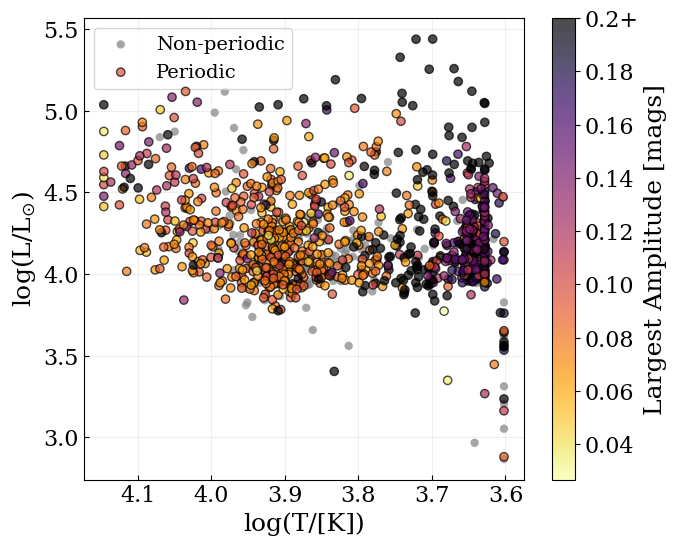

In [21]:
def basic_HRD(column, cbar_label='Largest Amplitude [mJy]'):
    plt.rcParams['font.family'] = 'serif'
    fig, ax = plt.subplots(figsize=(doc_width, 6))
    c = sample[column]
    mask = (sample['alarm_level_flag'] == 0).values
    nonvar_mask = (sample['alarm_level_flag'] == 1).values
    vmax = np.max(c[mask])
    vmax = 0.2
    # vmax = 80
    vmin = 0
    # norm_smc = Normalize(vmin=np.min(smc_c[mask_smc]), vmax=np.max(smc_c[mask_smc]))

    sc01 = ax.scatter(sample['logT'].values[nonvar_mask], sample['logL'].values[nonvar_mask], c='gray', alpha=0.7, edgecolors='none', label='Non-periodic')
    # LMC
    sc1 = ax.scatter(sample['logT'].values[mask], sample['logL'].values[mask],
                    c=c[mask], cmap='inferno_r', norm=Normalize(vmin=np.min(c[mask]), vmax=vmax),
                    alpha=0.7, zorder=10, edgecolors='black', label='Periodic')
    # ax.set_xlim(3.9, 3.95)
    # ax.set_ylim(4.2,4.4)
    ax.invert_xaxis()
    ax.set_xlabel('log(T/[K])', fontsize=18) # /K
    ax.set_ylabel('log(L/L$_{\\odot}$)', fontsize=18) #L_{\odot} 
    cbar = fig.colorbar(sc1, ax=ax, orientation='vertical')
    cbar.set_label(cbar_label, fontsize=18)
    cbar.ax.tick_params(labelsize=16)

    ticks = cbar.get_ticks()
    # tick_labels = [f'{tick:.0f}' for tick in ticks]
    # tick_labels[-1] = '80+'

    tick_labels = [f'{tick:.2f}' for tick in ticks]
    tick_labels[-1] = '0.2+'

    # cbar.set_ticks(ticks)
    cbar.set_ticklabels(tick_labels)
    plt.legend(loc='best', fontsize=14)
    plt.tick_params(axis='both', which='both', direction = 'in', labelsize=16)
    plt.grid(True, alpha=0.2)
    # plt.savefig(f'hr_diagrams/HR_{column}_shortened.png', dpi=300, bbox_inches='tight')
    plt.show()

basic_HRD('mag_amplitude_1', cbar_label='Largest Amplitude [mags]')# basic_HRD('best_period', cbar_label='Dominant Period [days]')


In [22]:
# loading in evolutionary models
eep_directory_lmc = '../MIST_models_LMC/'
evol_files_lmc = glob.glob(f'{eep_directory_lmc}*.track.*')
# order files by mass 
evol_files_lmc = sorted(evol_files_lmc, key=lambda x: float(x.split('/')[-1].split('M')[0]))
print(evol_files_lmc)

# loading in evolutionary models
eep_directory_smc = '../MIST_models_SMC/'
evol_files_smc = glob.glob(f'{eep_directory_smc}*.track.*')
# order files by mass 
evol_files_smc = sorted(evol_files_smc, key=lambda x: float(x.split('/')[-1].split('M')[0]))
print(evol_files_smc)

def Open_File(file_name):
    # Get the column names
    row = open(file_name, 'r').readlines()
    # It's the last comment in the file so get all the comments
    comments = [x for x in row if '#' in x  ]
    # Split the last row into individual keys, exclude the '#'
    columns = comments[-1].split()[1:]
    # Strip any blank spaces
    columns = [x.strip(' ') for x in columns]
    # Read in as pandas dataframe
    df = pd.read_csv(file_name, comment='#',names = columns,delimiter='\\s+')
    return df

df = Open_File(evol_files_lmc[0])

# Show the first few rows to check that everything looks okay
df.head()

['../MIST_models_LMC/0100000M.track.eep', '../MIST_models_LMC/0120000M.track.eep', '../MIST_models_LMC/0140000M.track.eep', '../MIST_models_LMC/0160000M.track.eep', '../MIST_models_LMC/0180000M.track.eep', '../MIST_models_LMC/0200000M.track.eep', '../MIST_models_LMC/0220000M.track.eep', '../MIST_models_LMC/0240000M.track.eep', '../MIST_models_LMC/0260000M.track.eep', '../MIST_models_LMC/0280000M.track.eep', '../MIST_models_LMC/0300000M.track.eep']
['../MIST_models_SMC/0080000M.track.eep', '../MIST_models_SMC/0100000M.track.eep', '../MIST_models_SMC/0120000M.track.eep', '../MIST_models_SMC/0140000M.track.eep', '../MIST_models_SMC/0160000M.track.eep', '../MIST_models_SMC/0180000M.track.eep', '../MIST_models_SMC/0200000M.track.eep', '../MIST_models_SMC/0220000M.track.eep', '../MIST_models_SMC/0240000M.track.eep', '../MIST_models_SMC/0260000M.track.eep', '../MIST_models_SMC/0280000M.track.eep', '../MIST_models_SMC/0300000M.track.eep']


,star_age,star_mass,star_mdot,he_core_mass,c_core_mass,o_core_mass,log_L,log_L_div_Ledd,log_LH,log_LHe,...,delta_Pg,nu_max,acoustic_cutoff,max_conv_vel_div_csound,max_gradT_div_grada,gradT_excess_alpha,min_Pgas_div_P,max_L_rad_div_Ledd,e_thermal,phase
0,188.556008,9.999994,-2.493013e-08,0.0,0.0,0.0,3.745870,-3.256312,-6.400387,-99.0,...,0.0,1.893734,17.416303,0.609349,8.451085,0.0,0.936616,0.087501,2.621026e+48,-1.0
1,196.367411,9.999994,-2.462060e-08,0.0,0.0,0.0,3.747962,-3.224769,-6.365151,-99.0,...,0.0,1.908613,17.549320,0.604683,8.453988,0.0,0.936616,0.087501,2.632676e+48,-1.0
2,204.576402,9.999994,-2.461793e-08,0.0,0.0,0.0,3.746160,-3.217131,-6.328506,-99.0,...,0.0,1.925511,17.704112,0.609983,8.454962,0.0,0.936616,0.087500,2.644848e+48,-1.0
3,213.158237,9.999994,-2.433761e-08,0.0,0.0,0.0,3.743090,-3.218162,-6.290684,-99.0,...,0.0,1.943529,17.870183,0.611085,8.449708,0.0,0.936617,0.087499,2.657486e+48,-1.0
4,222.008249,9.999994,-2.401834e-08,0.0,0.0,0.0,3.743028,-3.199991,-6.251972,-99.0,...,0.0,1.961084,18.030705,0.608620,8.449363,0.0,0.936618,0.087498,2.670513e+48,-1.0


In [23]:
def Get_MS(mist_df):
    # Phase = 0 corresponds to the main sequence
    MS = mist_df.loc[mist_df['phase'] == 0.0]
    return MS

def get_RGB(mist_df):
    # Phase = 2 corresponds to the RGB
    RGB = mist_df.loc[mist_df['phase'] == 2.0]
    return RGB

def get_phase(mist_df):
    # Phase = -1 is pre-main sequence
    # Phase = 6 is post-AGB
    # plot everything else 
    RGB = mist_df.loc[(mist_df['phase'] != -1.0) & (mist_df['phase'] != 6.0)]
    return RGB

In [24]:
def plot_evol_tracks_multiple(files, lmc=True):
    '''
    Create two similar HRD subplots side by side, with separate code blocks
    so each panel can be customized independently later.
    '''
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

    cmap = cm.copper
    norm = mcolors.Normalize(vmin=0, vmax=len(files) - 1)

    # -----------------------------
    # Left panel
    # -----------------------------
    for i, file_i in enumerate(files):
        df_i = Open_File(file_i)
        phase_i = get_phase(df_i)
        color = cmap(norm(i))

        ax_left.plot(phase_i['log_Teff'], phase_i['log_L'], "-", color=color, alpha=0.5, zorder=3)

        x_label = 4.071
        idx_near = (phase_i['log_Teff'] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, 'log_L']

        ax_left.annotate(
            str(int(file_i.split('/')[-1].split('.track')[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=12,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False
        )

    mask_left = sample[
        (sample['logT'] > 3.62)
        & (sample['logT'] < 4.05)
        & (sample['logL'] > 3.95)
        & (sample['logL'] < 5.48)
        & (sample['alarm_level_flag'] == 0)
    ]
    ax_left.vlines(3.62, 3.95, 5.5, color='gray', alpha=0.5, linestyle='--', zorder=20)
    ax_left.scatter(mask_left['logT'], mask_left['logL'], alpha=0.9, color='xkcd:sun yellow', edgecolors='xkcd:copper', label='YSG', zorder=8)
    ax_left.scatter(np.log10(rsg_smc['Temp']), rsg_smc['LogLum'], alpha=0.3, c='tab:red', label='RSG', zorder=6)
    ax_left.scatter(np.log10(rsg_lmc['Temp']), rsg_lmc['LogLum'], alpha=0.3, c='tab:red', zorder=6)

    sn_zorder = 4
    sn_color = "xkcd:cyan"
    ax_left.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt='o', color=sn_color, label='SN Progenitor', zorder=sn_zorder)
    ax_left.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_left.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt='o', color=sn_color, zorder=sn_zorder)

    ax_left.invert_xaxis()
    ax_left.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title_fontsize=16, fontsize=18, markerscale=1.5)
    ax_left.set_xlim(4.1, 3.59)
    ax_left.set_ylim(3.93, 5.48)
    ax_left.tick_params(axis='both', direction='in', labelsize=16)
    ax_left.set_xlabel('log(T/[K])', fontsize=24)
    ax_left.set_ylabel('log(L/[L$_☉$])', fontsize=24)

    # -----------------------------
    # Right panel (currently same as left; edit here independently)
    # -----------------------------
    for i, file_i in enumerate(files):
        df_i = Open_File(file_i)
        phase_i = get_phase(df_i)
        color = cmap(norm(i))

        ax_right.plot(phase_i['log_Teff'], phase_i['log_L'], "-", color=color, alpha=0.5, zorder=3)

        x_label = 4.071
        idx_near = (phase_i['log_Teff'] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, 'log_L']

        ax_right.annotate(
            str(int(file_i.split('/')[-1].split('.track')[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=12,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False
        )

    mask_right = sample[
        (sample['logT'] > 3.62)
        & (sample['logT'] < 4.05)
        & (sample['logL'] > 3.95)
        & (sample['logL'] < 5.48)
        & (sample['alarm_level_flag'] == 0)
    ]
    ax_right.vlines(3.62, 3.95, 5.5, color='gray', alpha=0.5, linestyle='--', zorder=20)
    ax_right.scatter(mask_right['logT'], mask_right['logL'], alpha=0.9, color='xkcd:orangey yellow', edgecolors='xkcd:copper', label='YSG', zorder=8)
    ax_right.scatter(np.log10(rsg_smc['Temp']), rsg_smc['LogLum'], alpha=0.3, c='tab:red', label='RSG', zorder=6)
    ax_right.scatter(np.log10(rsg_lmc['Temp']), rsg_lmc['LogLum'], alpha=0.3, c='tab:red', zorder=6)

    ax_right.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt='o', color=sn_color, label='SNIIb Progenitor', zorder=sn_zorder)
    ax_right.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt='o', color=sn_color, zorder=sn_zorder)
    ax_right.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt='o', color=sn_color, zorder=sn_zorder)

    ax_right.invert_xaxis()
    ax_right.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title_fontsize=16, fontsize=18, markerscale=1.5)
    ax_right.set_xlim(4.1, 3.59)
    ax_right.set_ylim(3.93, 5.48)
    ax_right.tick_params(axis='both', direction='in', labelsize=16)
    ax_right.set_xlabel('log(T/[K])', fontsize=24)
    ax_right.set_ylabel('log(L/[L$_☉$])', fontsize=24)

    fig.tight_layout()

# plot_evol_tracks_multiple(evol_files_smc[:-3][::-1], lmc=False)

In [ ]:
from archived_code.extras.alternate_scripts_for_feb_sept_lcs.view_and_clean_feb26 import df_extract
from archived_code.extras.alternate_scripts_for_feb_sept_lcs.view_and_clean_feb26 import offset_corrector
box1 = [307,286,756, 1189] #1168
# box4 = [1130,1182,911,978, 1101]
box2 = [716,541,579,1100]
box3 = [780,670,765, 378]
proposed = [307,1130,613,1085,716,953,250,890,156,40,780,522]
chosen = [40, 156, 250, 307, 522, 613,  716,   780,  890, 953, 1085, 1130, ]#, 522]
highL_cands = [403,534,585,596,602,720,725,741,744,785,877,889,1020,1028,1029,1037,1055,1058,1087,1095,1102,1117,1120,1131,1166,1187,1195,1201,1203,1211,1212,1213,1252]
new_highL_cands = [1261, 1058, 1174, 962, 1205, 1248, 864, 1224, 1114, 1110, 1103, 1159, 1267, 1163, 1078, 594]

# Lightcurves and time domain plots


Index 307 (15.993419 -71.90551)
Number of observations per telescope:
telescope
E    440
F    431
G    611
i    479
j    447
k    462
m    276
n    277
o    662
dtype: int64

Index 286 (15.61304 -72.279282)
Number of observations per telescope:
telescope
G    604
k    457
o    624
dtype: int64

Index 756 (84.721164 -70.717834)
Number of observations per telescope:
telescope
E    714
i    568
j    581
m    648
n    421
dtype: int64

Index 1189 (84.143504 -67.675377)
Number of observations per telescope:
telescope
F    482
G    813
i    540
j    707
k    637
n    474
o    729
dtype: int64


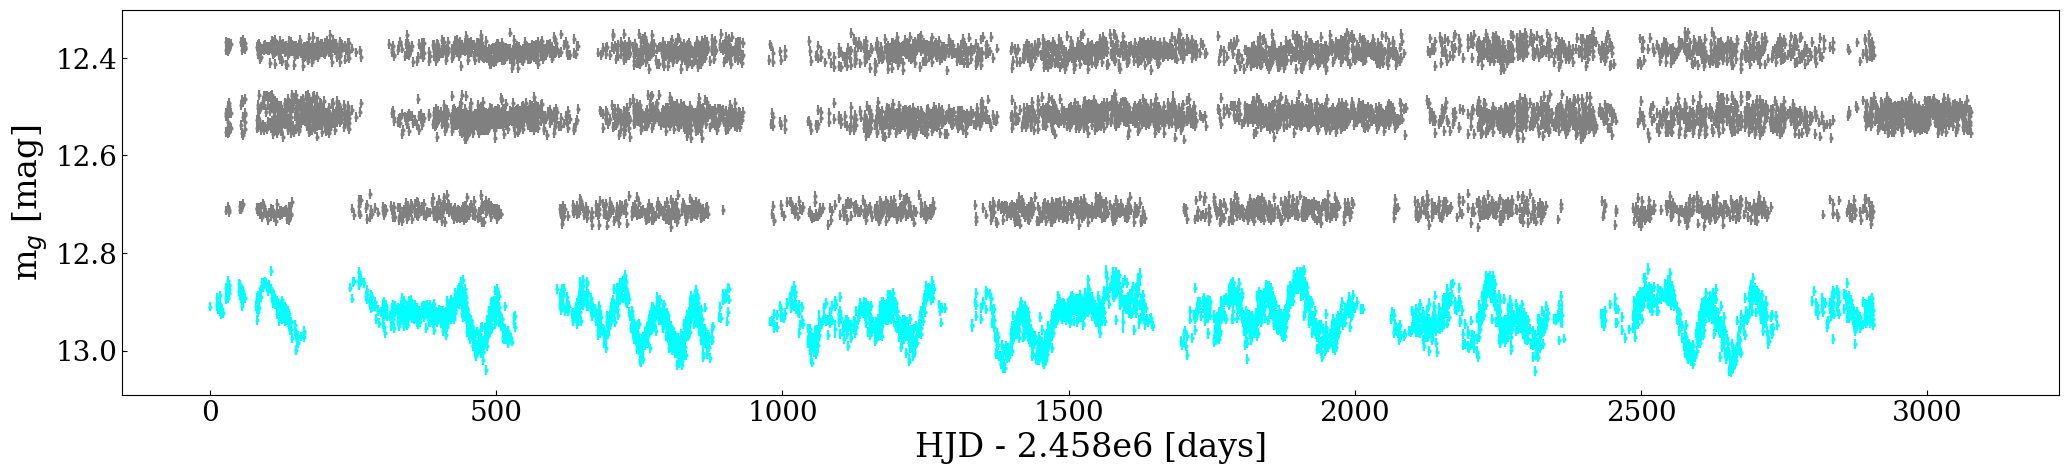

In [26]:
def individual_plotter(indices, tail=1, g=True, seeoutliers=False, report=True, bg=None, border_color=None, border_width=2.0):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    # Use Matplotlib's default color cycle (one color per star).
    cycle_colors = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
    if not cycle_colors:
        cycle_colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']

    band_label = 'g' if g else 'V'

    # First pass: load data and choose a global reference HJD0 so the x-axis is readable.
    loaded = []
    hjd0 = None
    for index in indices:
        # Filtered data (outliers removed by default).
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]
        loaded.append((index, df, fulldata, telescopes))
        candidate = float(np.nanmin(df['HJD'].values))
        if fulldata is not None:
            candidate = min(candidate, float(np.nanmin(fulldata['HJD'].values)))
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)

    # plt.figure(figsize=(12, 20))
    plt.figure(figsize=(25, 5))
    if bg is not None:
        # plt.gcf().patch.set_facecolor(bg)
        plt.gca().set_facecolor(bg)
    if border_color is not None:
        fig = plt.gcf()
        ax = plt.gca()
        for spine in ax.spines.values():
            spine.set_color(border_color)
            spine.set_linewidth(border_width)
        # fig.patch.set_edgecolor(border_color)
        # fig.patch.set_linewidth(border_width)
        fig.set_frameon(True)
    for j, (index, df, fulldata, telescopes) in enumerate(loaded):
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            print(df.groupby('telescope').size())

        color = cycle_colors[j % len(cycle_colors)]
        t = df['HJD'] - hjd0
        if index in proposed:
            # color=color
            color = 'cyan'
        else:
            color = 'grey'
            # color=color
        plt.errorbar(
            t,
            df['mag'],
            yerr=df['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=3,
            capsize=0,
            color=color,
            zorder=10,
            label=f"Star {index}",
        )


    plt.xlabel(f'HJD - 2.458e6 [days]', fontsize=24)
    plt.ylabel('m$_g$ [mag]', fontsize=24)
    # plt.title(f"{band_label}-band light curves ({len(indices)} stars)")
    # plt.legend()
    # plt.grid(True)
    plt.gca().invert_yaxis()  # Invert y-axis since smaller magnitudes are brighter
    # plt.style.use('dark_background')
    plt.tick_params(axis='both', direction='in', labelsize=20)
    
    # plt.savefig(f'figs/offsets_examples/{RA}{dec}_g.png')
    # plt.savefig('hr_diagrams/box3.png', bbox_inches='tight', dpi=300)
    # If saving, keep the chosen background (otherwise Matplotlib may default to white).
    # plt.savefig('./figs/misc/box3.png', bbox_inches='tight', dpi=300, facecolor=plt.gcf().get_facecolor())
    plt.show()
    return

individual_plotter(box1)


Index 696 (82.67394 -69.192993)
Number of observations per telescope:
telescope
E    725
i    595
m    675
dtype: int64


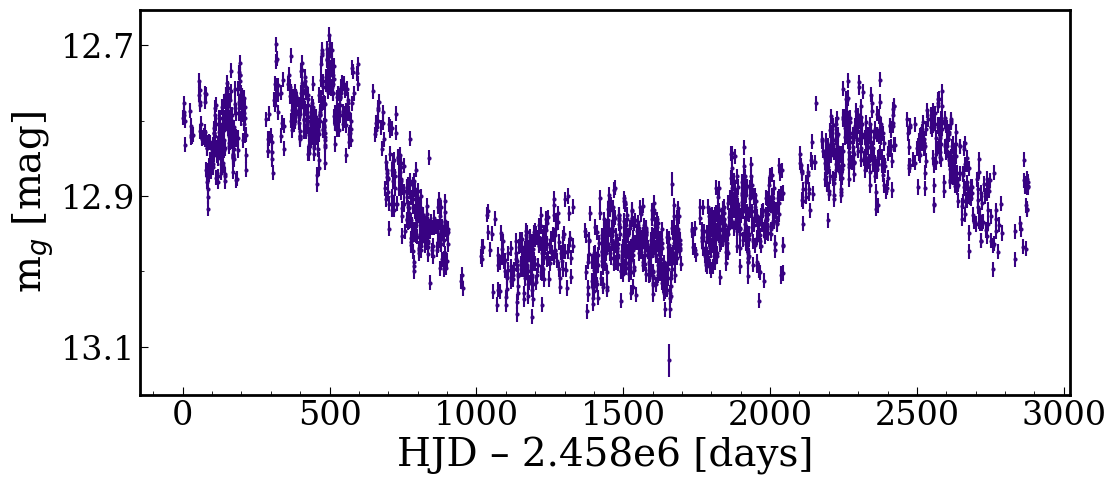

In [27]:
box1 = [307,286,756, 1189] #1168
# box4 = [1130,1182,911,978, 1101]
box2 = [716,541,579,1100]
box3 = [780,670,765, 378]
proposed = [307,1130,613,1085,716,953,250,890,156,40,780,522]


def individual_plotter(indices, tail=1, g=True, seeoutliers=False, report=True, bg=None, border_color=None, border_width=2.0):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    # Use Matplotlib's default color cycle (one color per star).
    cycle_colors = plt.rcParams['axes.prop_cycle'].by_key().get('color', [])
    if not cycle_colors:
        cycle_colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']

    band_label = 'g' if g else 'V'

    # First pass: load data and choose a global reference HJD0 so the x-axis is readable.
    loaded = []
    hjd0 = None
    for index in indices:
        # Filtered data (outliers removed by default).
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]
        loaded.append((index, df, fulldata, telescopes))
        candidate = float(np.nanmin(df['HJD'].values))
        if fulldata is not None:
            candidate = min(candidate, float(np.nanmin(fulldata['HJD'].values)))
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)

    # plt.figure(figsize=(12, 20))
    plt.figure(figsize=(12, 5))
    if bg is not None:
        # plt.gcf().patch.set_facecolor(bg)
        plt.gca().set_facecolor(bg)
    if border_color is not None:
        fig = plt.gcf()
        ax = plt.gca()
        for spine in ax.spines.values():
            spine.set_color(border_color)
            spine.set_linewidth(border_width)
        # fig.patch.set_edgecolor(border_color)
        # fig.patch.set_linewidth(border_width)
        fig.set_frameon(True)
    for j, (index, df, fulldata, telescopes) in enumerate(loaded):
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            print(df.groupby('telescope').size())

        color = cycle_colors[j % len(cycle_colors)]
        t = df['HJD'] - hjd0
        if index in proposed:
            color = 'cyan'
        else:
            # color = 'xkcd:sky'
            color='xkcd:indigo'
            # color=color
        plt.errorbar(
            t,
            df['mag'],
            yerr=df['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=3,
            capsize=0,
            color=color,
            zorder=10,
            # label=f"{band_label}-band (idx {index})",
        )


    plt.xlabel(f'HJD – 2.458e6 [days]', fontsize=28)
    plt.ylabel('m$_g$ [mag]', fontsize=28)
    # plt.title(f"{band_label}-band light curves ({len(indices)} stars)")
    # plt.legend()
    # plt.grid(True)
    plt.gca().invert_yaxis()  # Invert y-axis since smaller magnitudes are brighter
    plt.gca().xaxis.set_minor_locator(AutoMinorLocator(5))
    plt.gca().yaxis.set_minor_locator(AutoMinorLocator(2))
    plt.tick_params(axis='both', direction='in', labelsize=24, length=6)
    plt.tick_params(axis='y', which='minor', direction='in', length=3)
    ax = plt.gca()
    ax.set_yticks([12.7, 12.9, 13.1])
    plt.tick_params(axis='x', which='minor', direction='in', length=3)
    #set border width
    for spine in ax.spines.values():
        spine.set_linewidth(2.0)
    # plt.savefig(f'figs/offsets_examples/{RA}{dec}_g.png')
    # plt.savefig('hr_diagrams/box3.png', bbox_inches='tight', dpi=300)
    # plt.savefig('./figs/misc/696lc.png', bbox_inches='tight', dpi=300)
    # If saving, keep the chosen background (otherwise Matplotlib may default to white).
    # Example: plt.savefig('hr_diagrams/box3.png', bbox_inches='tight', dpi=300, facecolor=plt.gcf().get_facecolor())
    plt.style.use('default')
    plt.show()

individual_plotter([696], g=True, seeoutliers=False, report=True)#, border_color='xkcd:burnt orange', bg = 'xkcd:light peach', border_width=3.0)
# individual_plotter([1025], g=True, seeoutliers=False, report=True)#, border_color='green', bg = 'xkcd:very light green', border_width=3.0)

/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/657305007.py:171: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


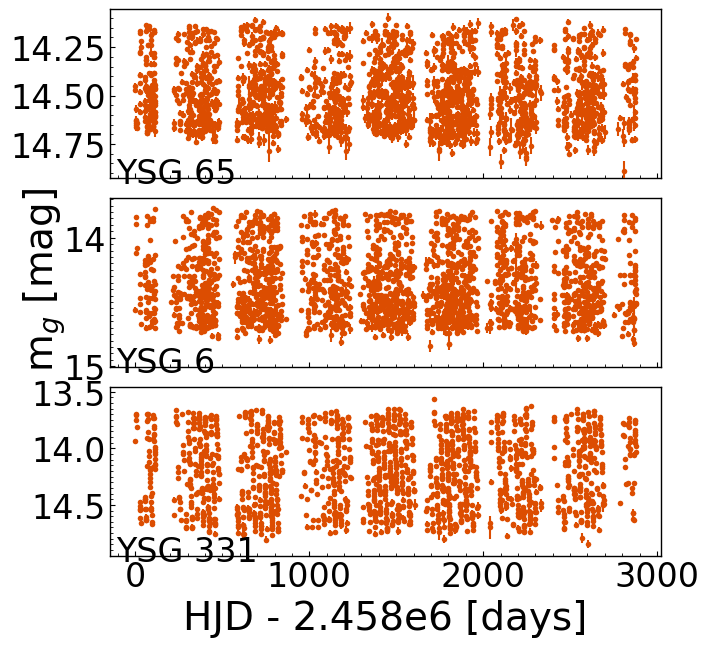

(<Figure size 710.001x709.8 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: xlabel='HJD - 2.458e6 [days]'>],
       dtype=object))

In [28]:
def stacked_lightcurve_panels(
    indices,
    *,
    g=True,
    seeoutliers=False,
    report=True,
    bg=None,
    bg_alpha=0.2,
    border_color=None,
    border_width=1.0,
    sharex=True,
    figsize=(doc_width, 2.366),
    marker_size=4,
    label_fontsize=28,
    tick_labelsize=24,
    show=True,
    savepath=None,
):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    n = len(indices)
    if n == 0:
        raise ValueError("No indices were provided")

    fig, axes = plt.subplots(
        nrows=n,
        ncols=1,
        figsize=(figsize[0], figsize[1] * n),
        sharex=sharex,
        gridspec_kw={"hspace": 0.12},
    )
    if n == 1:
        axes = [axes]

    loaded = []
    hjd0 = None
    for index in indices:
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]

        candidates = []
        if df is not None and 'HJD' in df and len(df) > 0:
            hjd_vals = df['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if fulldata is not None and 'HJD' in fulldata and len(fulldata) > 0:
            hjd_vals = fulldata['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if not candidates:
            if report:
                print(f"Index {index}: no valid HJD values; skipping")
            continue

        candidate = min(candidates)
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)
        loaded.append((index, df, telescopes, fulldata))

    if not loaded:
        raise ValueError("No plottable light-curve data found for the provided indices")

    for i, (index, df, telescopes, fulldata) in enumerate(loaded):
        ax = axes[i]
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            if 'telescope' in df:
                print(df.groupby('telescope').size())
            else:
                print("(no filtered points)")

        if bg is not None:
            ax.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
        if border_color is not None:
            for spine in ax.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)

        t = df['HJD'] - hjd0
        # t = t[t < 2900]
        df_plot = df.loc[t.index]
        ax.errorbar(
            t,
            df_plot['mag'],
            yerr=df_plot['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=marker_size,
            capsize=0,
            color='xkcd:deep orange',
            zorder=10,
        )

        if fulldata is not None and len(fulldata) > 0:
            t_full = fulldata['HJD'] - hjd0
            ax.plot(
                t_full,
                fulldata['mag'],
                linestyle='none',
                marker='o',
                markersize=max(1, marker_size - 1),
                markeredgecolor='none',
                color='xkcd:deep orange',
                alpha=0.20,
                zorder=1,
            )

        #### LABEL WITH YSG NUMBER
        # ax.text(
        #     0.01,
        #     0.95,
        #     f'{index}',
        #     transform=ax.transAxes,
        #     ha='left',
        #     va='top',
        #     fontsize=tick_labelsize,
        #     # fontweight='bold',
        # )
        ax.text(0.01,
                0.12,
                f'YSG {index}',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=tick_labelsize,
                # fontweight='bold',
                zorder = 20
                )
        # ax.text(
        #     0.03,
        #     0.75,
        #     # f'{RA:.4f}, {dec:.4f}',
        #     transform=ax.transAxes,
        #     ha='left',
        #     va='top',
        #     fontsize=max(10, label_fontsize - 6),
        # )

        ax.set_ylabel('')
        # ax.xaxis.grid(True, which='minor')
        # turn on minor ticks
        # ax.yaxis.set_major_locator(MultipleLocator(0.2))
        ax.yaxis.set_minor_locator(MultipleLocator(0.05))
        ax.xaxis.set_minor_locator(MultipleLocator(100))
        ax.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        # set axis limits
        # amp = df['mag'].max() - df['mag'].min()
        amp = sample.iloc[index]['mag_amplitude_1']
        ax.set_ylim(sample.iloc[index]['overall_mean_mag'] + 0.7 * amp, sample.iloc[index]['overall_mean_mag'] - 0.7 * amp)


        # ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.1f}'))
        
    

        if i < n - 1:
            ax.set_xlabel('')
            ax.tick_params(labelbottom=False)
        else:
            ax.set_xlabel('HJD - 2.458e6 [days]', fontsize=label_fontsize)

    fig.supylabel('m$_g$ [mag]', fontsize=label_fontsize, x=0.0, y=0.5, rotation=90)
    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, axes

low_amp = [286, 756, 1189, 670]
box1 = [307,286,756, 1189] #1168
# box4 = [1130,1182,911,978, 1101]
box2 = [716,541,579,1100]
box3 = [780,670,765, 378]
longp = [696,1057,1130]
cephs = [65, 6, 331]
reg = [213,803,]
# Example:
stacked_lightcurve_panels(cephs, g=True, seeoutliers=False, report=False, border_color='black', bg='white', savepath='./figs/misc/cephs_stacked_lc.pdf')

/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/1090468033.py:242: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


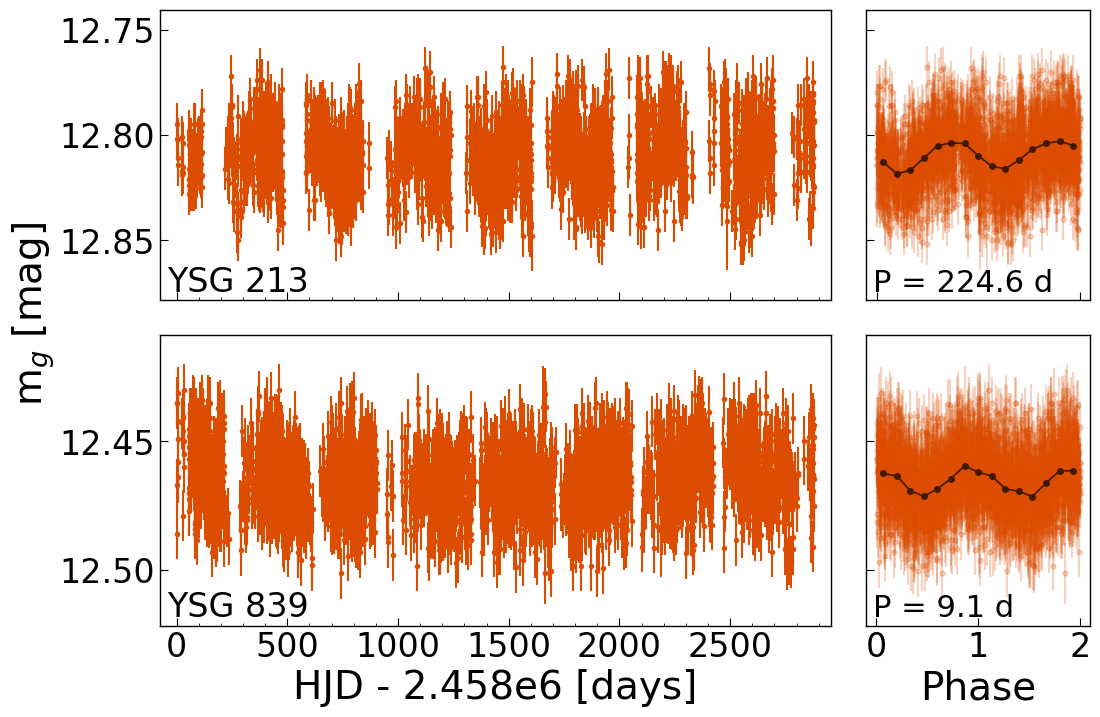

(<Figure size 1200x800 with 4 Axes>,
 ([<Axes: >, <Axes: xlabel='HJD - 2.458e6 [days]'>],
  [<Axes: >, <Axes: xlabel='Phase'>]))

In [29]:
def stacked_lightcurve_with_phasefold(
    indices,
    *,
    g=True,
    seeoutliers=False,
    report=True,
    bg=None,
    bg_alpha=0.2,
    border_color=None,
    border_width=1.0,
    sharex=True,
    figsize=(12, 4),
    marker_size=4,
    label_fontsize=28,
    tick_labelsize=24,
    width_ratios=(3, 1),
    wspace=0.08,
    # phase-fold specific
    phase_bins=2,
    samples_per_peak=5,
    auto=False,
    binned_phase=False,
    phase_nbins=30,
    phase_marker_size=3.5,
    show=True,
    savepath=None,
):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    n = len(indices)
    if n == 0:
        raise ValueError("No indices were provided")

    fig = plt.figure(figsize=(figsize[0], figsize[1] * n))
    gs = fig.add_gridspec(
        nrows=n,
        ncols=2,
        width_ratios=width_ratios,
        hspace=0.12,
        wspace=wspace,
    )
    axes_lc = [fig.add_subplot(gs[i, 0]) for i in range(n)]
    axes_phase = [fig.add_subplot(gs[i, 1]) for i in range(n)]
    # Phase panels are intentionally not sharex-linked across rows since each
    # star can have a different best period.

    if sharex:
        for i in range(1, n):
            axes_lc[i].sharex(axes_lc[0])

    loaded = []
    hjd0 = None
    for index in indices:
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]

        candidates = []
        if df is not None and 'HJD' in df and len(df) > 0:
            hjd_vals = df['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if fulldata is not None and 'HJD' in fulldata and len(fulldata) > 0:
            hjd_vals = fulldata['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if not candidates:
            if report:
                print(f"Index {index}: no valid HJD values; skipping")
            continue

        candidate = min(candidates)
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)
        loaded.append((index, df, telescopes, fulldata))

    if not loaded:
        raise ValueError("No plottable light-curve data found for the provided indices")

    for i, (index, df, telescopes, fulldata) in enumerate(loaded):
        ax_lc = axes_lc[i]
        ax_ph = axes_phase[i]
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            if 'telescope' in df:
                print(df.groupby('telescope').size())
            else:
                print("(no filtered points)")

        if bg is not None:
            ax_lc.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
            ax_ph.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
        if border_color is not None:
            for spine in ax_lc.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)
            for spine in ax_ph.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)

        # ---- Light curve panel (unchanged from stacked_lightcurve_panels) ----
        t = df['HJD'] - hjd0
        df_plot = df.loc[t.index]
        ax_lc.errorbar(
            t,
            df_plot['mag'],
            yerr=df_plot['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=marker_size,
            capsize=0,
            color='xkcd:deep orange',
            zorder=10,
        )

        if fulldata is not None and len(fulldata) > 0:
            t_full = fulldata['HJD'] - hjd0
            ax_lc.plot(
                t_full,
                fulldata['mag'],
                linestyle='none',
                marker='o',
                markersize=max(1, marker_size - 1),
                markeredgecolor='none',
                color='xkcd:deep orange',
                alpha=0.20,
                zorder=1,
            )

        ax_lc.text(
            0.01, 0.12, f'YSG {index}',
            transform=ax_lc.transAxes,
            ha='left', va='top',
            fontsize=tick_labelsize,
            zorder=20,
        )

        ax_lc.set_ylabel('')
        ax_lc.yaxis.set_minor_locator(MultipleLocator(0.05))
        ax_lc.xaxis.set_minor_locator(MultipleLocator(100))
        # set major x labels
        ax_lc.xaxis.set_major_locator(MultipleLocator(500))
        ax_lc.tick_params(axis='both', which='major', length=6)
        ax_lc.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        ax_lc.set_xlim(t.min() - 75, t.max() + 75)

        amp = sample.iloc[index]['mag_amplitude_1']
        mean_mag = sample.iloc[index]['overall_mean_mag']
        
        # ax_lc.set_ylim(mean_mag + 0.8 * amp, mean_mag - 0.7 * amp)
        ax_lc.set_ylim(mean_mag + 1 * amp, mean_mag - 1 * amp)

        # Lock the phase panel to the same y-scale as the light curve panel
        ax_ph.sharey(ax_lc)

        if i < n - 1:
            ax_lc.set_xlabel('')
            ax_lc.tick_params(labelbottom=False)
        else:
            ax_lc.set_xlabel('HJD - 2.458e6 [days]', fontsize=label_fontsize)

        # ---- Phase-fold panel ----
        lombs = compute_lomb_scargle(
            index,
            df=df,
            telescopes=telescopes,
            g=g,
            auto=auto,
            samples_per_peak=samples_per_peak,
            report=False,
            show=False,
            correct_offsets=True,
        )
        best_period = lombs['best_period']

        time = np.asarray(df['HJD'])
        mags = np.asarray(df['mag'])
        mag_err = np.asarray(df['mag_err'])
        phased_time = (time / best_period) % phase_bins

        for j, telescope in enumerate(telescopes):
            mask = df['telescope'] == telescope
            ax_ph.errorbar(
                phased_time[mask],
                mags[mask],
                yerr=mag_err[mask],
                fmt='o',
                color='xkcd:deep orange',
                markersize=phase_marker_size,
                alpha=0.25 if binned_phase else 0.85,
            )

        if binned_phase:
            bins = np.linspace(0.0, float(phase_bins), int(phase_nbins) + 1)
            centers = 0.5 * (bins[:-1] + bins[1:])
            which = np.digitize(phased_time, bins) - 1
            binned_mag = np.full(int(phase_nbins), np.nan)
            for k in range(int(phase_nbins)):
                m = mags[which == k]
                if m.size > 0:
                    binned_mag[k] = np.nanmedian(m)
            valid = np.isfinite(binned_mag)
            ax_ph.plot(
                centers[valid], binned_mag[valid], '-o',
                color='xkcd:chocolate brown', markersize=4, linewidth=1.2, zorder=12,
            )

        # No separate invert_yaxis() here: ax_ph now shares its y-axis with
        # ax_lc (see sharey above), and ax_lc's set_ylim(top, bottom) call
        # already inverts the shared axis. Calling invert_yaxis() again would
        # flip it back and undo the inversion for both panels.
        ax_ph.set_ylabel('')
        # ax_ph.yaxis.tick_right()
        ax_ph.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        # make major ticks bigger
        ax_ph.tick_params(axis='both', which='major', length=6)
        ax_ph.tick_params(labelleft=False)
        ax_ph.text(
            0.03, 0.11, f'P = {best_period:.1f} d',
            transform=ax_ph.transAxes,
            ha='left', va='top',
            fontsize=tick_labelsize - 2,
        )


        if i < n - 1:
            ax_ph.set_xlabel('')
            ax_ph.tick_params(labelbottom=False)
        else:
            ax_ph.set_xlabel('Phase', fontsize=label_fontsize)
            ax_ph.tick_params(axis='x', which='major', direction='in', length=6)
            ax_ph.xaxis.set_major_locator(MultipleLocator(1))

    fig.supylabel('m$_g$ [mag]', fontsize=label_fontsize, x=0.0, y=0.5, rotation=90)
    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, (axes_lc, axes_phase)

low_amp = [286, 756, 1189, 670]
box1 = [307, 286, 756, 1189]  # 1168
box2 = [716, 541, 579, 1100]
box3 = [780, 670, 765, 378]
longp = [696, 1057, 1130]
cephs = [65, 6, 331]
reg = [213, 839]#,902]

# Example:
stacked_lightcurve_with_phasefold(
    reg,
    g=True,
    seeoutliers=False,
    report=False,
    border_color='black',
    bg='white',
    binned_phase=True,
    phase_nbins=15,
    # savepath='./figs/misc/reg_stacked_lc_with_phasefold.pdf',
)

<>:274: SyntaxWarning: invalid escape sequence '\%'
<>:274: SyntaxWarning: invalid escape sequence '\%'
/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/4241063427.py:274: SyntaxWarning: invalid escape sequence '\%'
  0.98, false_alarm_level * 1.15, '$P_{false}=1\%$',
/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/4241063427.py:313: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


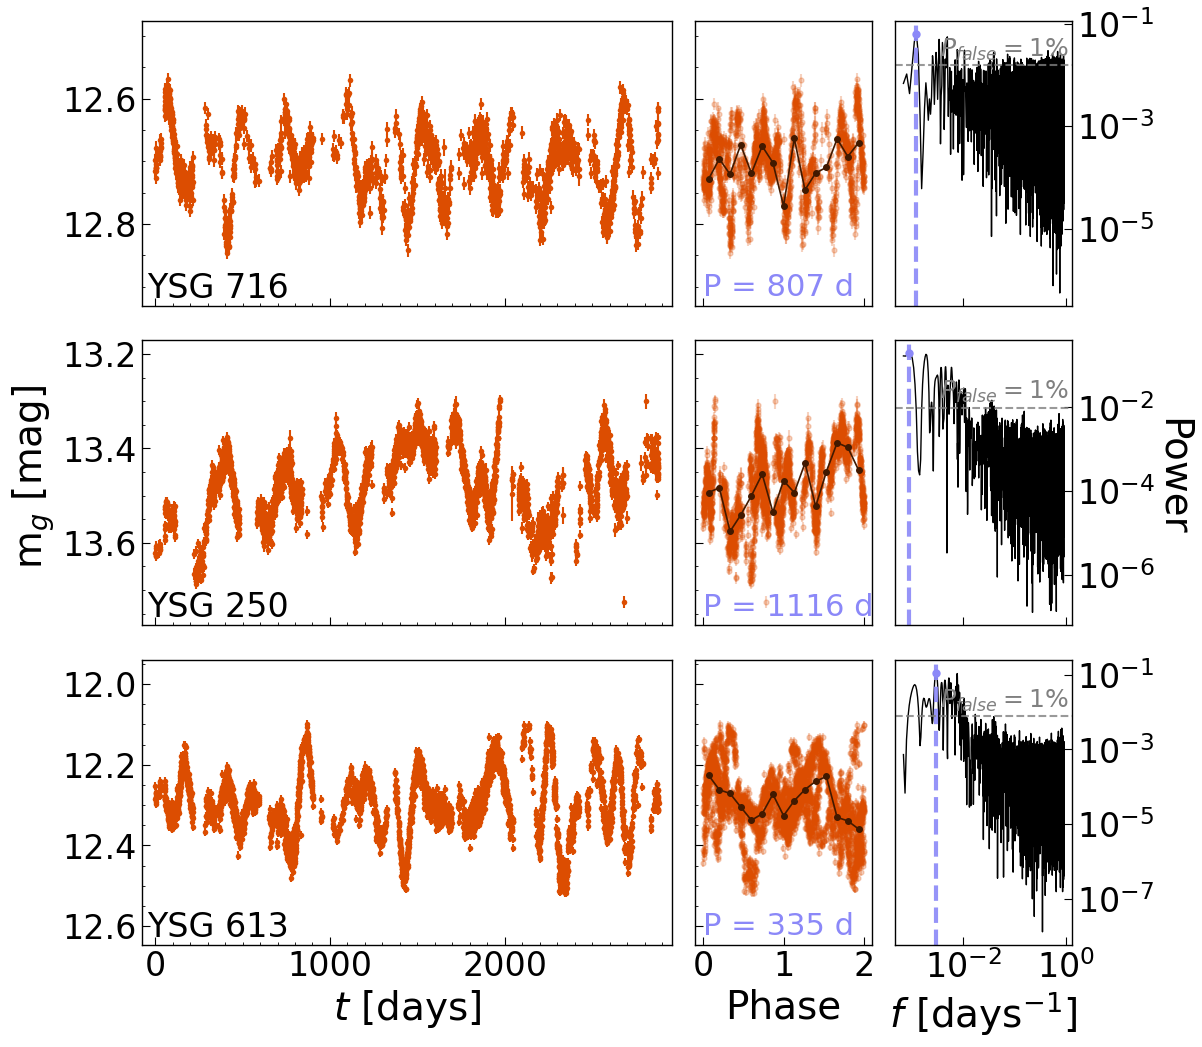

(<Figure size 1200x1200 with 9 Axes>,
 ([<Axes: >, <Axes: >, <Axes: xlabel='$t$ [days]'>],
  [<Axes: >, <Axes: >, <Axes: xlabel='Phase'>],
  [<Axes: >, <Axes: >, <Axes: xlabel='$f$ [days$^{-1}$]'>]))

In [30]:
def stacked_lightcurve_with_phasefold(
    indices,
    *,
    g=True,
    seeoutliers=False,
    report=True,
    bg=None,
    bg_alpha=0.2,
    border_color=None,
    border_width=1.0,
    sharex=True,
    # figsize=(doc_width*2, 2.366*2),
    figsize=(12, 4),
    marker_size=4,
    label_fontsize=28,
    tick_labelsize=24,
    width_ratios=(3, 1, 1),
    wspace=0.08,
    # phase-fold specific
    phase_bins=2,
    samples_per_peak=5,
    auto=False,
    binned_phase=False,
    phase_nbins=30,
    phase_marker_size=3.5,
    # periodogram specific
    per_xlim=(0, 0.9),
    show=True,
    savepath=None,
):
    if isinstance(indices, (int, np.integer)):
        indices = [int(indices)]
    else:
        indices = [int(i) for i in indices]

    n = len(indices)
    if n == 0:
        raise ValueError("No indices were provided")

    fig = plt.figure(figsize=(figsize[0], figsize[1] * n))
    gs = fig.add_gridspec(
        nrows=n,
        ncols=3,
        width_ratios=width_ratios,
        hspace=0.12,
        wspace=wspace,
    )
    axes_lc = [fig.add_subplot(gs[i, 0]) for i in range(n)]
    axes_phase = [fig.add_subplot(gs[i, 1]) for i in range(n)]
    axes_per = [fig.add_subplot(gs[i, 2]) for i in range(n)]
    # Phase and periodogram panels are intentionally not sharex-linked across
    # rows since each star can have a different best period.

    if sharex:
        for i in range(1, n):
            axes_lc[i].sharex(axes_lc[0])

    loaded = []
    hjd0 = None
    for index in indices:
        df, telescopes = offset_corrector(index, g=g, show=False)
        fulldata = None
        if seeoutliers:
            fulldata = df_extract(index, g=g, seeoutliers=True, report=False)[0]

        candidates = []
        if df is not None and 'HJD' in df and len(df) > 0:
            hjd_vals = df['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if fulldata is not None and 'HJD' in fulldata and len(fulldata) > 0:
            hjd_vals = fulldata['HJD'].dropna().values
            if hjd_vals.size:
                candidates.append(float(np.nanmin(hjd_vals)))
        if not candidates:
            if report:
                print(f"Index {index}: no valid HJD values; skipping")
            continue

        candidate = min(candidates)
        hjd0 = candidate if (hjd0 is None) else min(hjd0, candidate)
        loaded.append((index, df, telescopes, fulldata))

    if not loaded:
        raise ValueError("No plottable light-curve data found for the provided indices")

    for i, (index, df, telescopes, fulldata) in enumerate(loaded):
        ax_lc = axes_lc[i]
        ax_ph = axes_phase[i]
        ax_per = axes_per[i]
        RA = coords['RA'].iloc[index]
        dec = coords['DEC'].iloc[index]

        if report:
            print(f"\nIndex {index} ({RA} {dec})")
            print("Number of observations per telescope:")
            if 'telescope' in df:
                print(df.groupby('telescope').size())
            else:
                print("(no filtered points)")

        if bg is not None:
            ax_lc.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
            ax_ph.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
            ax_per.set_facecolor(mcolors.to_rgba(bg, alpha=float(bg_alpha)))
        if border_color is not None:
            for spine in ax_lc.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)
            for spine in ax_ph.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)
            for spine in ax_per.spines.values():
                spine.set_color(border_color)
                spine.set_linewidth(border_width)

        # ---- Light curve panel (unchanged) ----
        t = df['HJD'] - hjd0
        df_plot = df.loc[t.index]
        ax_lc.errorbar(
            t,
            df_plot['mag'],
            yerr=df_plot['mag_err'],
            fmt='o',
            markeredgecolor='none',
            markersize=marker_size,
            capsize=0,
            color='xkcd:deep orange',
            zorder=10,
        )

        if fulldata is not None and len(fulldata) > 0:
            t_full = fulldata['HJD'] - hjd0
            ax_lc.plot(
                t_full,
                fulldata['mag'],
                linestyle='none',
                marker='o',
                markersize=max(1, marker_size - 1),
                markeredgecolor='none',
                color='xkcd:deep orange',
                alpha=0.20,
                zorder=1,
            )

        ax_lc.text(
            0.01, 0.12, f'YSG {index}',
            transform=ax_lc.transAxes,
            ha='left', va='top',
            fontsize=tick_labelsize,
            zorder=20,
        )

        ax_lc.set_ylabel('')
        ax_lc.yaxis.set_minor_locator(MultipleLocator(0.05))
        ax_lc.xaxis.set_minor_locator(MultipleLocator(100))
        # set major x labels
        ax_lc.xaxis.set_major_locator(MultipleLocator(1000))
        ax_lc.tick_params(axis='both', which='major', length=6)
        ax_lc.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        ax_lc.set_xlim(t.min() - 75, t.max() + 75)

        amp = sample.iloc[index]['mag_amplitude_1']
        mean_mag = sample.iloc[index]['overall_mean_mag']
        #for cephs:
        # ax_lc.set_ylim(mean_mag + 0.8 * amp, mean_mag - 0.7 * amp)
        # for regs:
        ax_lc.set_ylim(mean_mag + 1 * amp, mean_mag - 1 * amp)

        # Lock the phase panel to the same y-scale as the light curve panel
        ax_ph.sharey(ax_lc)

        if i < n - 1:
            ax_lc.set_xlabel('')
            ax_lc.tick_params(labelbottom=False)
        else:
            # ax_lc.set_xlabel('HJD - 2.458x$10^6$ [days]', fontsize=label_fontsize)
            ax_lc.set_xlabel('$t$ [days]', fontsize=label_fontsize)

        # ---- Phase-fold panel (unchanged) ----
        lombs = compute_lomb_scargle(
            index,
            df=df,
            telescopes=telescopes,
            g=g,
            auto=auto,
            samples_per_peak=samples_per_peak,
            report=False,
            show=False,
            correct_offsets=True,
        )
        best_period = lombs['best_period']

        time = np.asarray(df['HJD'])
        mags = np.asarray(df['mag'])
        mag_err = np.asarray(df['mag_err'])
        phased_time = (time / best_period) % phase_bins

        for j, telescope in enumerate(telescopes):
            mask = df['telescope'] == telescope
            ax_ph.errorbar(
                phased_time[mask],
                mags[mask],
                yerr=mag_err[mask],
                fmt='o',
                color='xkcd:deep orange',
                markersize=phase_marker_size,
                alpha=0.25 if binned_phase else 0.85,
            )

        if binned_phase:
            bins = np.linspace(0.0, float(phase_bins), int(phase_nbins) + 1)
            centers = 0.5 * (bins[:-1] + bins[1:])
            which = np.digitize(phased_time, bins) - 1
            binned_mag = np.full(int(phase_nbins), np.nan)
            for k in range(int(phase_nbins)):
                m = mags[which == k]
                if m.size > 0:
                    binned_mag[k] = np.nanmedian(m)
            valid = np.isfinite(binned_mag)
            ax_ph.plot(
                centers[valid], binned_mag[valid], '-o',
                color='xkcd:chocolate brown', markersize=4, linewidth=1.2, zorder=12,
            )

        # No separate invert_yaxis() here: ax_ph shares its y-axis with
        # ax_lc (see sharey above), and ax_lc's set_ylim(top, bottom) call
        # already inverts the shared axis. Calling invert_yaxis() again would
        # flip it back and undo the inversion for both panels.
        ax_ph.set_ylabel('')
        # ax_ph.yaxis.tick_right()
        ax_ph.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        # make major ticks bigger
        ax_ph.tick_params(axis='both', which='major', length=6)
        ax_ph.tick_params(labelleft=False)
        if best_period < 100:
            labelP = f'P = {best_period:.1f} d'
        else:
            labelP = f'P = {best_period:.0f} d'
        ax_ph.text(
            0.045, 0.115, labelP,
            transform=ax_ph.transAxes,
            ha='left', va='top',
            fontsize=tick_labelsize - 2,
            color='xkcd:lavender blue'
        )
        

        if i < n - 1:
            ax_ph.set_xlabel('')
            ax_ph.tick_params(labelbottom=False)
        else:
            ax_ph.set_xlabel('Phase', fontsize=max(14, label_fontsize - 0))
            ax_ph.tick_params(axis='x', which='major', direction='in', length=6)
            ax_ph.xaxis.set_major_locator(MultipleLocator(1))

        # ---- Periodogram panel ----
        ax_per.plot(lombs['frequency'], lombs['power'], color='xkcd:black', linewidth=1.0)
        best_frequency = lombs['best_frequency']
        false_alarm_level = lombs['false_alarm_level']
        if best_frequency > 0:
            ax_per.axvline(best_frequency, color='xkcd:lavender blue', linestyle='--', linewidth=3.0, alpha=0.9)
            best_idx = np.argmin(np.abs(lombs['frequency'] - best_frequency))
            ax_per.plot(
                lombs['frequency'][best_idx], lombs['power'][best_idx],
                'o', color='xkcd:lavender blue', markersize=5,
            )
        ax_per.axhline(false_alarm_level, color='grey', linestyle='--', alpha=0.8)
        # annotate right above this line "False Alarm Level"
        # annotate right above this line
        ax_per.set_yscale('log')
        ax_per.set_xscale('log')
        ax_per.text(
            0.98, false_alarm_level * 1.15, '$P_{false}=1\%$',
            # 0.98, false_alarm_level - false_alarm_level * 0.7, 'False Alarm\nLevel',
            color='grey', fontsize=18,
            ha='right', va='bottom', rotation=0,
            transform=ax_per.get_yaxis_transform(),
        )
        # if not auto and per_xlim is not None:
        #     ax_per.set_xlim(*per_xlim)
        #     ax_per.set_xlim(None, 0.9)
        #     ax_per.set_xlim(None,0.1)
        
        # ax_per.ticklabel_format(style='plain', axis='x', useOffset=False)
        # ax_per.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: '0' if x == 0 else f'{x:g}'))
        # ax_per.xaxis.set_minor_locator(MultipleLocator(0.25))

        # ax_per.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.1f}'))

        ax_per.set_ylabel('')
        ax_per.tick_params(axis='both', which='both', direction='in', labelsize=tick_labelsize)
        ax_per.tick_params(axis='both', which='major', length=6)
        ax_per.tick_params(axis='x', labelbottom=True)
        ax_per.yaxis.tick_right()
        # labels for ticks on the right side of the periodogram
        ax_per.tick_params(axis='y', which='both', labelright=True, labelleft=False)
        ax_per.yaxis.set_label_position("right")
        if i < n - 1:
            ax_per.set_xlabel('')
            ax_per.tick_params(labelbottom=False)
        else:
            ax_per.set_xlabel('$f$ [days$^{-1}$]', fontsize=max(14, label_fontsize - 0))
            ax_per.tick_params(axis='x', which='major', direction='in', length=6)



    # fig.supylabel('m$_g$ [mag]', fontsize=label_fontsize, x=0.0, y=0.5, rotation=90)
    fig.supylabel('m$_g$ [mag]', fontsize=label_fontsize, x=0.015, y=0.5, rotation=90)
    # y label on other side for periodogram
    fig.text(1.00, 0.5, 'Power', fontsize=label_fontsize, rotation=270, va='center', ha='right')
    
    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, (axes_lc, axes_phase, axes_per)

low_amp = [286, 756, 1189, 670]
box1 = [307, 286, 756, 1189]  # 1168
box2 = [716, 541, 579, 1100]
box3 = [780, 670, 765, 378]
longp = [696, 1130, 1057]
cephs = [65, 6, 331]
reg = [539, 839,902]
proposed_excerpt = [716, 250, 613]

# Example:
stacked_lightcurve_with_phasefold(
    proposed_excerpt,
    g=True,
    seeoutliers=False,
    report=False,
    border_color='black',
    bg='white',
    binned_phase=True,
    phase_nbins=15,
    savepath='./jared_meeting/logP_semiregs_stacked.png',
)

# some settings for cephs:
#phase_nbins = 30

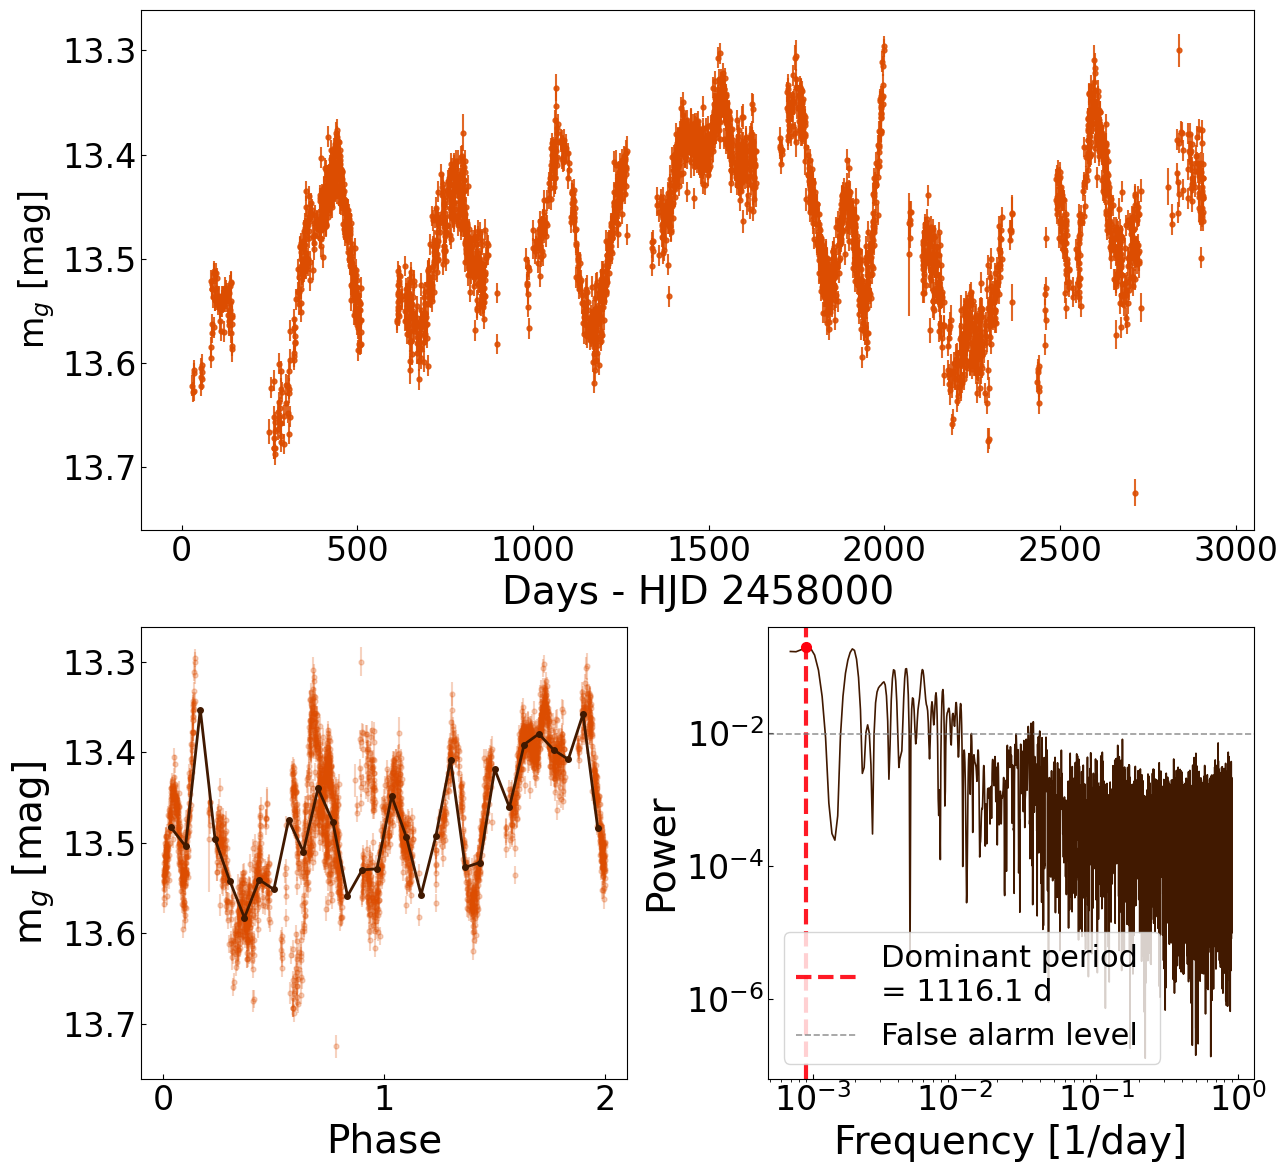

In [ ]:
from archived_code.extras.alternate_scripts_for_feb_sept_lcs.view_and_clean_feb26 import df_extract, offset_corrector
from archived_code.extras.alternate_scripts_for_feb_sept_lcs.metrics_feb26 import compute_lomb_scargle

def plot_three_panel_star_split(index, g=True, correct_offsets=True, phase_bins=2, samples_per_peak=5, 
                                label_fontsize=28,
                                tick_labelsize=24, auto=False, binned_phase=False, phase_nbins=30, savepath=None, show=True):
    if correct_offsets:
        df, telescopes = offset_corrector(index, additive=False, show=False)
    else:
        df, telescopes = df_extract(index, g=g)

    lombs = compute_lomb_scargle(
        index,
        df=df,
        telescopes=telescopes,
        g=g,
        auto=auto,
        samples_per_peak=samples_per_peak,
        report=False,
        show=False,
        correct_offsets=correct_offsets,
    )

    best_period = lombs['best_period']
    best_frequency = lombs['best_frequency']
    false_alarm_level = lombs['false_alarm_level']

    time = np.asarray(df['HJD'])
    mags = np.asarray(df['mag'])
    mag_err = np.asarray(df['mag_err'])
    phased_time = (time / best_period) % phase_bins

    RA = coords['RA'].iloc[index]
    dec = coords['DEC'].iloc[index]

    fig = plt.figure(figsize=(13, 12))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.15, 1.0])
    ax_lc = fig.add_subplot(gs[0, :])
    ax_phase = fig.add_subplot(gs[1, 0])
    ax_per = fig.add_subplot(gs[1, 1])
    # fig.suptitle(f'Index {index}: {RA} {dec}', fontsize=16, y=0.995)

    for j, telescope in enumerate(telescopes):
        mask = df['telescope'] == telescope
        label = 'Data' if j == 0 else None
        ax_lc.errorbar(
            time[mask] - 2458000,
            mags[mask],
            yerr=mag_err[mask],
            fmt='o',
            color='xkcd:deep orange',
            # ecolor='black',
            # markeredgecolor='black',
            markersize=3.5,
            # capsize=2,
            alpha=0.85,
            label=label,
        )
    ax_lc.set_ylabel('m$_g$ [mag]', fontsize=tick_labelsize)
    ax_lc.invert_yaxis()
    ax_lc.set_xlabel('Days - HJD 2458000', fontsize=label_fontsize)
    ax_lc.tick_params(axis='both', direction='in', labelsize=tick_labelsize)
    # ax_lc.grid(True, alpha=0.25)
    # ax_lc.legend(loc='best', fontsize=16)

    for j, telescope in enumerate(telescopes):
        mask = df['telescope'] == telescope
        label = 'Data' if j == 0 else None
        ax_phase.errorbar(
            phased_time[mask],
            mags[mask],
            yerr=mag_err[mask],
            fmt='o',
            color='xkcd:deep orange',
            # ecolor='xkcd:burnt orange',
            # markeredgecolor='black',
            markersize=3.5,
            # capsize=2,
            alpha=0.25 if binned_phase else 0.85,
            label=label,
        )
    if binned_phase:
        bins = np.linspace(0.0, float(phase_bins), int(phase_nbins) + 1)
        centers = 0.5 * (bins[:-1] + bins[1:])
        which = np.digitize(phased_time, bins) - 1
        binned_mag = np.full(int(phase_nbins), np.nan)
        for i in range(int(phase_nbins)):
            m = mags[which == i]
            if m.size > 0:
                binned_mag[i] = np.nanmedian(m)
        valid = np.isfinite(binned_mag)
        ax_phase.plot(centers[valid], binned_mag[valid], '-o', color='xkcd:chocolate brown', markersize=4, linewidth=2, label='Binned median', zorder=12)
    ax_phase.set_xlabel(f'Phase', fontsize=label_fontsize)
    ax_phase.set_ylabel('m$_g$ [mag]', fontsize=label_fontsize)
    ax_phase.invert_yaxis()
    ax_phase.tick_params(axis='both', direction='in', labelsize=tick_labelsize)
    # ax_phase.grid(True, alpha=0.25)
    # ax_phase.legend(loc='best', fontsize=16)

    ax_per.plot(lombs['frequency'], lombs['power'], color='xkcd:chocolate brown', linewidth=1.2)
    if best_frequency > 0:
        ax_per.axvline(best_frequency, color='xkcd:bright red', linestyle='--', linewidth=3, alpha=0.9, label=f'Dominant period \n= {best_period:.1f} d')
        best_idx = np.argmin(np.abs(lombs['frequency'] - best_frequency))
        ax_per.plot(lombs['frequency'][best_idx], lombs['power'][best_idx], 'o', color='xkcd:bright red', markersize=7)
    ax_per.axhline(false_alarm_level, color='grey', linestyle='--', alpha=0.8, linewidth=1.2, label=f'False alarm level')
    ax_per.set_xscale('log')
    ax_per.set_yscale('log')
    # if not auto:
    #     ax_per.set_xlim(0, 0.2)
        # ax_per.set_ylim(0, lombs['frequency'][best_idx]+ lombs['frequency'][best_idx]*0.5)
    # ax_per.ticklabel_format(style='plain', axis='x', useOffset=False)
    # ax_per.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.2f}'))
    # ax_per.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.3f}'))
    ax_per.set_xlabel('Frequency [1/day]', fontsize=label_fontsize)
    ax_per.set_ylabel('Power', fontsize=label_fontsize)
    ax_per.tick_params(axis='both', direction='in', labelsize=tick_labelsize)
    # ax_per.grid(True, alpha=0.25)
    ax_per.legend(loc='best', fontsize=22)

    fig.tight_layout(rect=[0, 0, 1, 0.985])

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, (ax_lc, ax_phase, ax_per), lombs

# Example:
fig, axes, lombs = plot_three_panel_star_split(250, binned_phase=True, phase_nbins=30, savepath="./figs/jared_figs/250_three_panel.png")

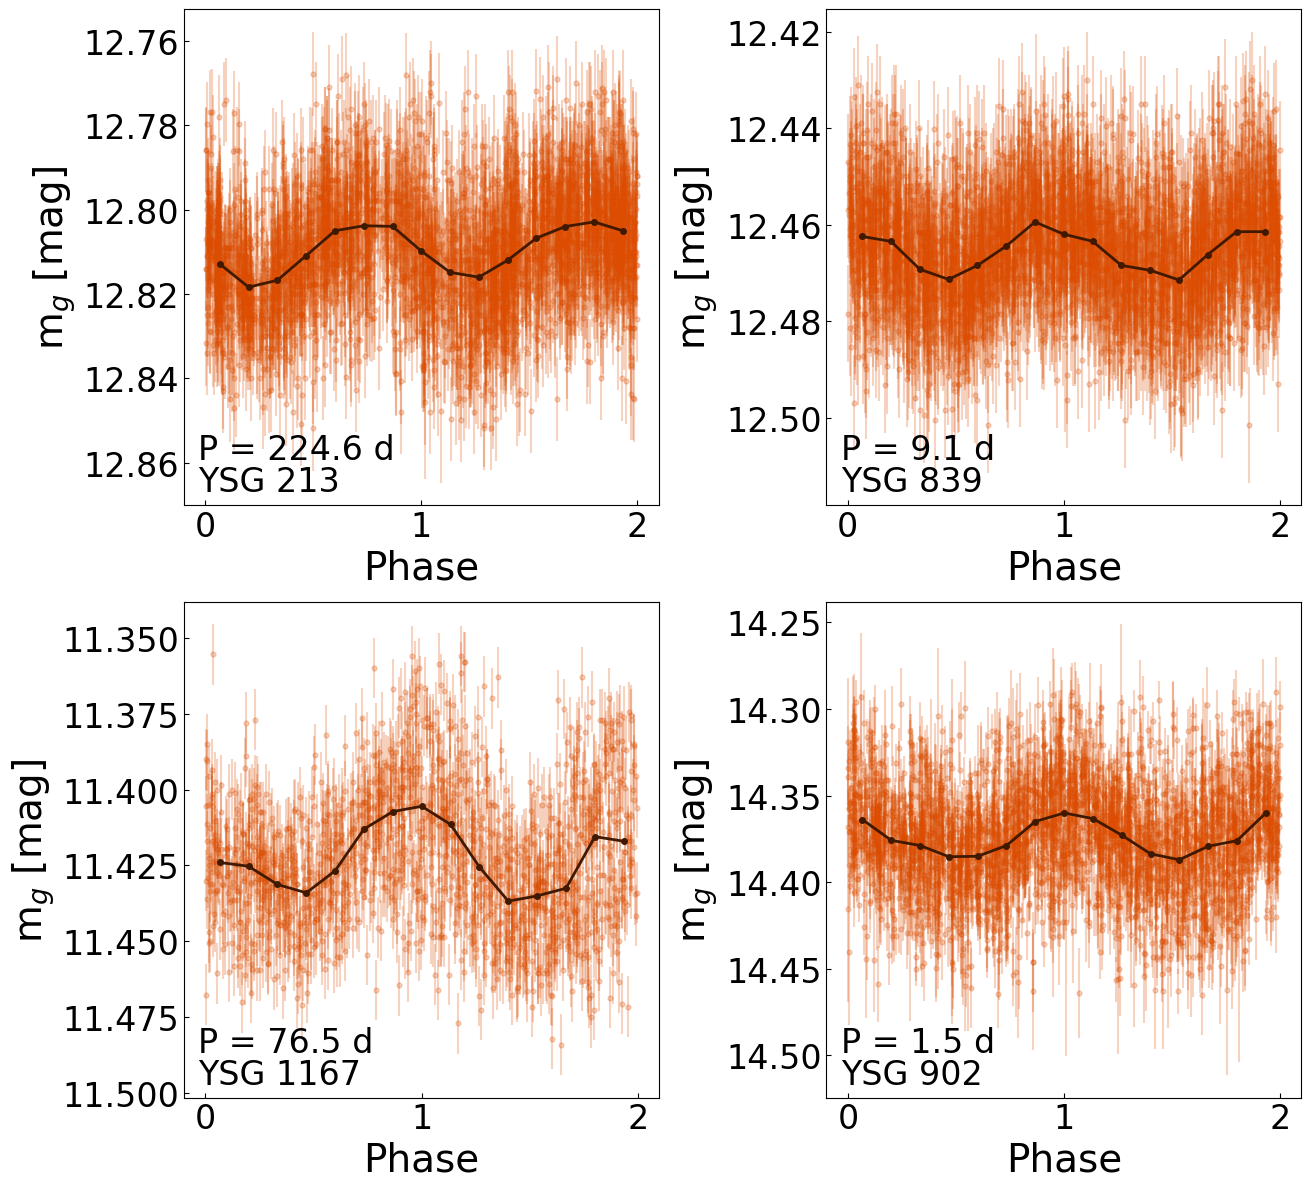

In [32]:
def plot_four_star_phasefold(indices, g=True, correct_offsets=True, phase_bins=1,
                              samples_per_peak=5, auto=False, binned_phase=False,
                              label_fontsize=28,
                                  tick_labelsize=24,
                              phase_nbins=30, savepath=None, show=True):
    """
    Phase-folded light curve panel for each of 4 star indices, arranged 2x2.

    Parameters
    ----------
    indices : list/tuple of 4 ints
        The star indices to plot (one panel each).
    Other parameters mirror plot_four_panel_phasefold.
    """
    assert len(indices) == 4, "indices must contain exactly 4 star indices"

    fig, axes = plt.subplots(2, 2, figsize=(13, 12))
    axes = axes.flatten()

    results = {}

    for ax, index in zip(axes, indices):
        if correct_offsets:
            df, telescopes = offset_corrector(index, additive=False, show=False)
        else:
            df, telescopes = df_extract(index, g=g)

        lombs = compute_lomb_scargle(
            index,
            df=df,
            telescopes=telescopes,
            g=g,
            auto=auto,
            samples_per_peak=samples_per_peak,
            report=False,
            show=False,
            correct_offsets=correct_offsets,
        )

        best_period = lombs['best_period']

        time = np.asarray(df['HJD'])
        mags = np.asarray(df['mag'])
        mag_err = np.asarray(df['mag_err'])
        phased_time = (time / best_period) % phase_bins

        for j, telescope in enumerate(telescopes):
            mask = df['telescope'] == telescope
            label = 'Data' if j == 0 else None
            ax.errorbar(
                phased_time[mask],
                mags[mask],
                yerr=mag_err[mask],
                fmt='o',
                color='xkcd:deep orange',
                markersize=3.5,
                alpha=0.25 if binned_phase else 0.85,
                label=label,
            )

        if binned_phase:
            bins = np.linspace(0.0, float(phase_bins), int(phase_nbins) + 1)
            centers = 0.5 * (bins[:-1] + bins[1:])
            which = np.digitize(phased_time, bins) - 1
            binned_mag = np.full(int(phase_nbins), np.nan)
            for i in range(int(phase_nbins)):
                m = mags[which == i]
                if m.size > 0:
                    binned_mag[i] = np.nanmedian(m)
            valid = np.isfinite(binned_mag)
            ax.plot(centers[valid], binned_mag[valid], '-o', color='xkcd:chocolate brown',
                    markersize=4, linewidth=2, label='Binned median', zorder=12)
            ax.text(
                    0.03,
                    0.08,
                    f'YSG {index}',
                    transform=ax.transAxes,
                    ha='left',
                    va='top',
                    fontsize=tick_labelsize,
                    # fontweight='bold',
                    )
            ax.text(
                    0.03,
                    0.145,
                    f'P = {best_period:.1f} d',
                    transform=ax.transAxes,
                    ha='left',
                    va='top',
                    fontsize=tick_labelsize,
                    # fontweight='bold',
                    )

        # ax.set_title(f'Index {index}  (P = {best_period:.1f} d)', fontsize=18)
        ax.set_xlabel('Phase', fontsize=label_fontsize)
        ax.set_ylabel('m$_g$ [mag]', fontsize=label_fontsize)
        ax.invert_yaxis()
        ax.tick_params(axis='both', direction='in', labelsize=tick_labelsize)

        results[index] = lombs

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(savepath, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, axes, results

# Example:
fig, axes, lombs = plot_four_star_phasefold(
    [213, 839, 1167, 902],
    binned_phase=True,
    phase_bins=2,
    phase_nbins=15,
    savepath="./figs/misc/four_star_phasefold.pdf"
)

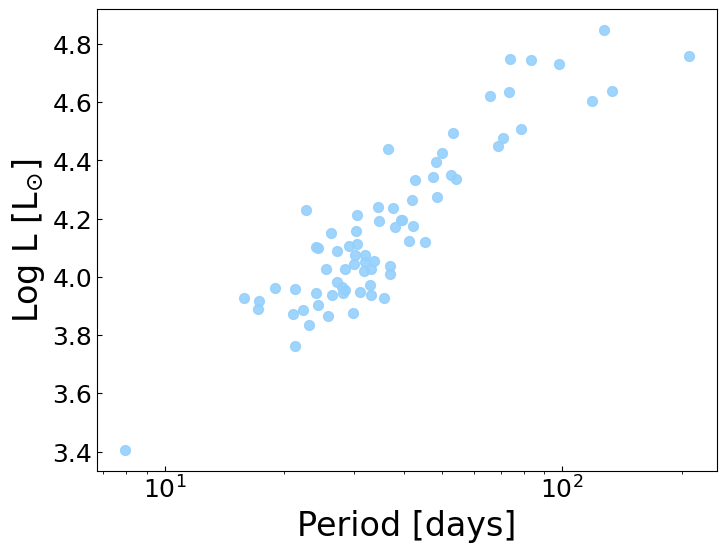

In [33]:
# classical cepheids period luminosity

fig, ax = plt.subplots(figsize=(8, 6))
cepheids = sample[sample['SIMBAD_maintype'] == 'ClassicalCep']

ax.scatter(cepheids['best_period'], cepheids['logL'], color='xkcd:light blue', s=50, alpha=0.9)
# ax.scatter(cepheids['best_period'], cepheids['logL'], color='xkcd:deep orange', s=50, alpha=0.85)
ax.set_xlabel('Period [days]', fontsize=24)
ax.set_ylabel('Log L [L$_{\\odot}$]', fontsize=24)
ax.set_xscale('log')
# ax.invert_yaxis()
ax.tick_params(axis='both', direction='in', labelsize=18)
# ax.set_title('Classical Cepheids Period-Luminosity Relation', fontsize=20)
plt.savefig('./figs/jared_figs/classical_cepheids_period_luminosity.png', dpi=300, bbox_inches='tight')

<>:21: SyntaxWarning: invalid escape sequence '\o'
<>:21: SyntaxWarning: invalid escape sequence '\o'
/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/1714737689.py:21: SyntaxWarning: invalid escape sequence '\o'
  ax1.set_ylabel('log (L/[L$_\odot$])', fontsize=24)


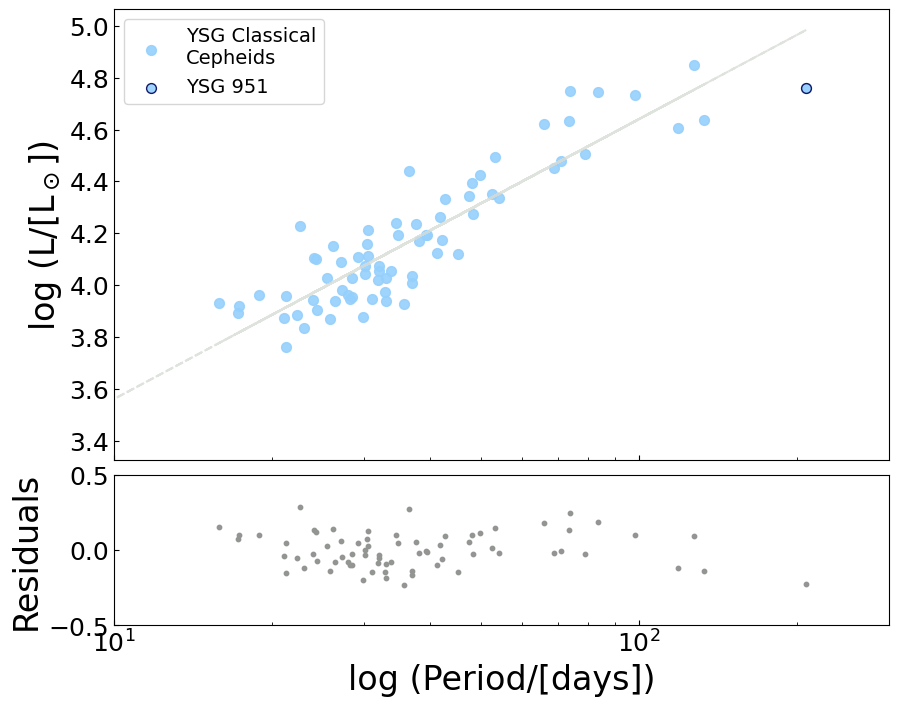

In [34]:
# classical cepheids period luminosity
fig, (ax1, ax2) = plt.subplots(figsize=(10, 8), gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05}, nrows=2, ncols=1, sharex=True)
cepheids = sample[sample['SIMBAD_maintype'] == 'ClassicalCep']

# ax.scatter(cepheids['best_period'], cepheids['overall_mean_mag'], color='xkcd:light blue', s=50, alpha=0.85)
ax1.scatter(cepheids['best_period'], cepheids['logL'], color='xkcd:light blue', s=50, alpha=0.9, label='YSG Classical\nCepheids')
# filter for star_ = 951
ax1.scatter(cepheids[cepheids['star_idx'] == 951]['best_period'], cepheids[cepheids['star_idx'] == 951]['logL'], marker='o', color='xkcd:light blue', edgecolor='xkcd:dark blue', s=50, alpha=0.9, label='YSG 951')
# fit a line
x = np.log10(cepheids['best_period'])
y = cepheids['logL']
coeffs = np.polyfit(x[:-1], y[:-1], 1)
ax1.plot(cepheids['best_period'], coeffs[0] * np.log10(cepheids['best_period']) + coeffs[1],  color='xkcd:light gray', linestyle='--', alpha=0.8)
# residuals
residuals = y - (coeffs[0] * x + coeffs[1])
# second plot

ax2.scatter(cepheids['best_period'], residuals, color='xkcd:gray', s=10)

ax2.set_xlabel('log (Period/[days])', fontsize=24)
ax1.set_ylabel('log (L/[L$_\odot$])', fontsize=24)
ax2.set_ylabel('Residuals', fontsize=24)
ax2.set_xscale('log')
ax2.set_xlim(10, 300)
ax1.legend(loc = 'upper left', fontsize=14)
ax2.set_ylim(-0.5, 0.5)
# ax.invert_yaxis()
ax1.tick_params(axis='both', which='both', direction='in', labelsize=18)
ax2.tick_params(axis='both', which='both', direction='in', labelsize=18)
plt.savefig('./figs/jared_figs/classical_cepheids_period_luminosity_residuals.png', dpi=300, bbox_inches='tight')
# ax.set_title('Classical Cepheids Period-Luminosity Relation', fontsize=20)

<>:10: SyntaxWarning: invalid escape sequence '\o'
<>:10: SyntaxWarning: invalid escape sequence '\o'
/var/folders/34/3847lqd14j78mfm70_z1c_r00000gn/T/ipykernel_79569/2687902953.py:10: SyntaxWarning: invalid escape sequence '\o'
  ax.set_ylabel('log (L/[L$_\odot$])', fontsize=24)


periods longer than 100 days:
star_idx
491      491
853      853
951      951
1072    1072
Name: star_idx, dtype: int64


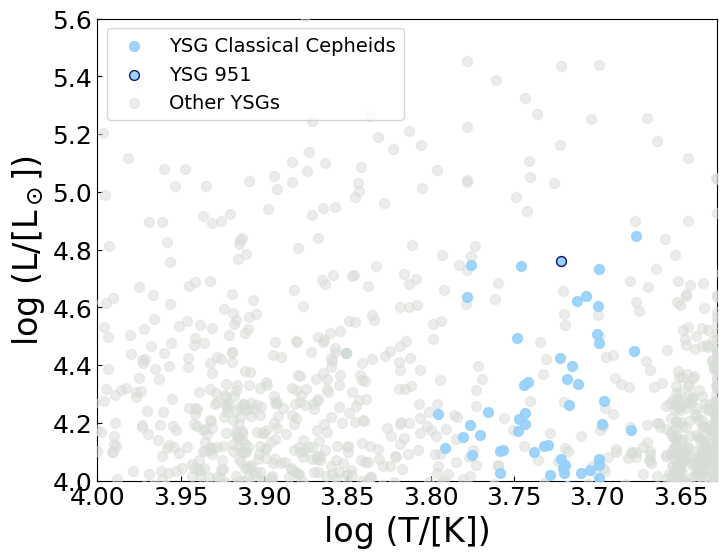

In [35]:
# cepheid HRD
fig, ax = plt.subplots(figsize=(8, 6))
cepheids = sample[sample['SIMBAD_maintype'] == 'ClassicalCep']
not_cepheids = sample[sample['SIMBAD_maintype'] != 'ClassicalCep']
ax.scatter(cepheids['logT'], cepheids['logL'], color='xkcd:light blue', label = 'YSG Classical Cepheids', s=50, alpha=0.9, zorder = 10)
ax.scatter(cepheids[cepheids['star_idx'] == 951]['logT'], cepheids[cepheids['star_idx'] == 951]['logL'], marker='o', color='xkcd:light blue', edgecolor='xkcd:dark blue', s=50, alpha=0.9, label='YSG 951', zorder = 15)
ax.scatter(cepheids[cepheids['star_idx'] == 1083]['logT'], cepheids[cepheids['star_idx'] == 1083]['logL'], marker='o',color='xkcd:light gray', s=50, alpha=0.9, zorder=20)
ax.scatter(not_cepheids['logT'], not_cepheids['logL'], color='xkcd:light gray', label = 'Other YSGs', s=50, alpha=0.5, zorder = 5)
ax.set_xlabel('log (T/[K])', fontsize=24)
ax.set_ylabel('log (L/[L$_\odot$])', fontsize=24)
ax.set_xlim(3.628, 4.0)
ax.set_ylim(4.0, 5.6)
ax.invert_xaxis()
ax.tick_params(axis='both', direction='in', labelsize=18)
ax.legend(loc = 'upper left', fontsize=14)
plt.savefig('./figs/jared_figs/classical_cepheids_HRD.png', dpi=300, bbox_inches='tight')
print("periods longer than 100 days:")
print(cepheids[cepheids['best_period'] > 100]['star_idx'])

# HRDs

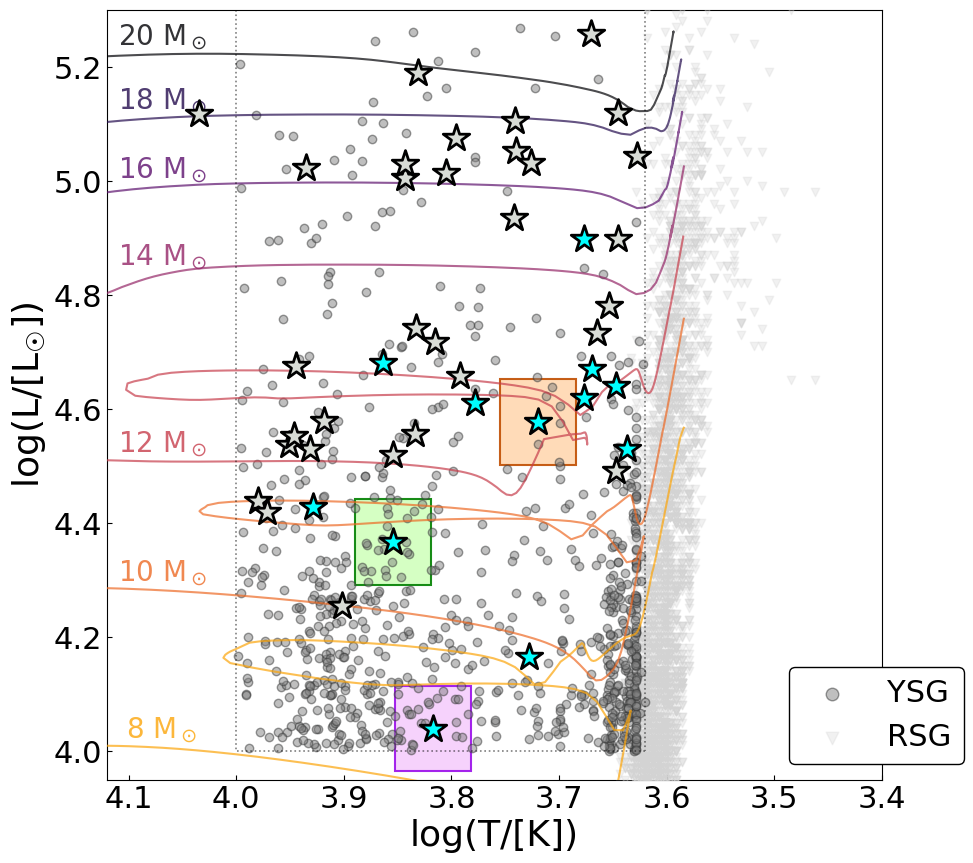

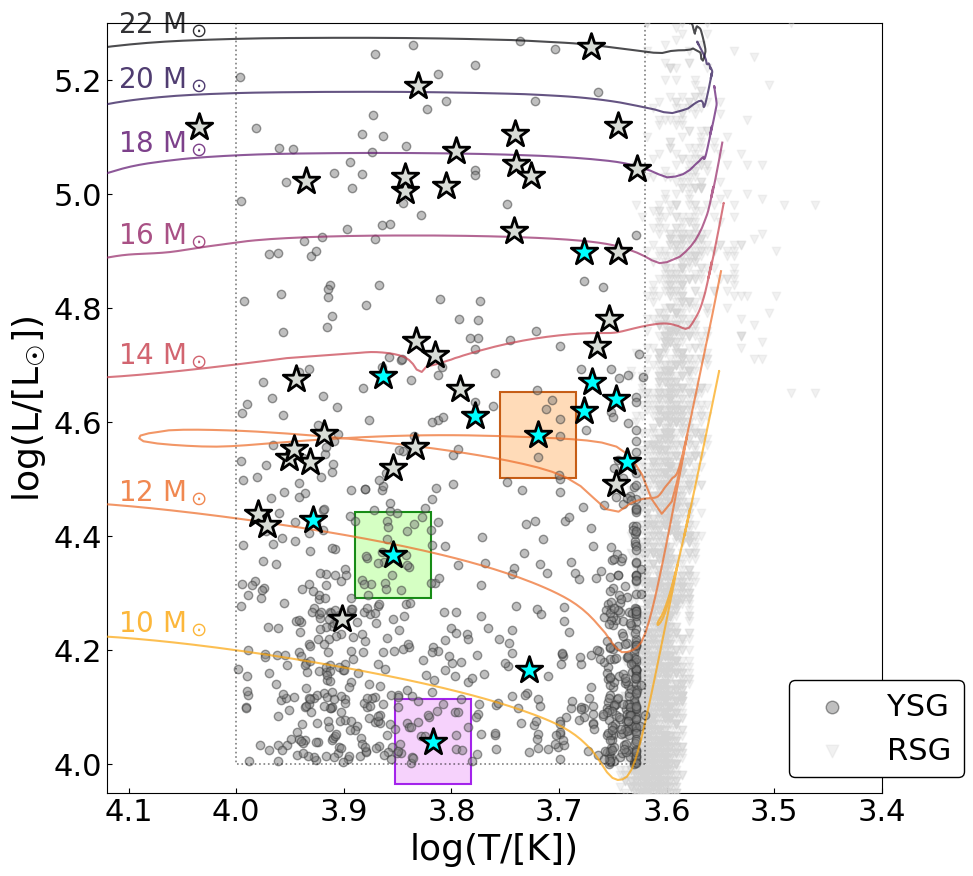

In [36]:
def plot_hrd(evol_track_files,
    *,
    open_file_func=None,
    var_df=None,
    rsg_smc_df=None,
    rsg_lmc_df=None,
    boxes=None,
    box_styles=None,
    proposed_indices=None,
    individual_plotter_func=None,
    figsize=(10, 10),
    width_ratios=(1.15, 1.0),
    hrd_xlim=(4.12, 3.40),
    hrd_ylim=(3.93, 5.48),
    ysg_box=(3.62, 4.00, 4.00, 5.48),
    savepath=None,
    dpi=300,
    report=False,
):
    if open_file_func is None:
        open_file_func = Open_File
    if var_df is None:
        var_df = sample
    if rsg_smc_df is None:
        rsg_smc_df = rsg_smc
    if rsg_lmc_df is None:
        rsg_lmc_df = rsg_lmc
    if boxes is None:
        boxes = [box3, box1, box2]
    if proposed_indices is None:
        proposed_indices = proposed
    if individual_plotter_func is None:
        individual_plotter_func = individual_plotter

    if box_styles is None:
        box_styles = [
            {"border_color": "xkcd:burnt orange", "bg": "xkcd:light peach", "border_width": 3.0},
            {"border_color": "green", "bg": "xkcd:very light green", "border_width": 3.0},
            {"border_color": "xkcd:violet", "bg": "xkcd:very light purple", "border_width": 3.0}
        ]

    if len(boxes) != 3:
        raise ValueError("Expected exactly 3 boxes (e.g., [box1, box2, box3])")
    # fig = plt.figure(figsize=figsize)
    fig, ax_hrd = plt.subplots(figsize=figsize)
    # Slightly larger gap between the left and right columns.
    gs = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.31)

    # -----------------------------
    # Left panel: HRD
    # -----------------------------
    # ax_hrd = fig.add_subplot(gs[0, 0])

    cmap = cm.inferno
    norm = mcolors.Normalize(vmin=0, vmax=len(evol_track_files) - 1)
    new_cmap = truncate_colormap(cmap, 0.0, 0.8, n=len(evol_track_files))

    for i, file_i in enumerate(evol_track_files):
        df_i = open_file_func(file_i)
        phase_i = get_phase(df_i)
        color = new_cmap(norm(i))

        ax_hrd.plot(
            phase_i["log_Teff"],
            phase_i["log_L"],
            "-",
            color=color,
            alpha=0.7,
            zorder=17,
        )

        x_label = 4.069
        idx_near = (phase_i["log_Teff"] - x_label).abs().idxmin()
        y_label = phase_i.loc[idx_near, "log_L"]

        # Mass annotation
        ax_hrd.annotate(
            str(int(file_i.split("/")[-1].split(".track")[0][1:3])) + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=20,
            color=color,
            zorder=20,
            alpha=0.8,
            annotation_clip=False,
        )


    x0, x1, y0, y1 = ysg_box
    mask = var_df[
        (var_df["logT"] > x0)
        & (var_df["logT"] < x1)
        & (var_df["logL"] > y0)
        & (var_df["logL"] < y1)
        # & (var_df["alarm_level_flag"] == 0)
        # & (var_df["alarm_level_flag"].notna())
    ]
    # ax_hrd.fill_betweenx([y0, y1], x0, x1, color="xkcd:yellow tan", alpha=0.2, zorder=1)
    ax_hrd.add_patch(Rectangle((3.62, 4.0),0.38,1.6,facecolor='none',edgecolor='black',
                alpha=0.5,
                zorder=20,
                linewidth=1.2,
                linestyle='dotted',
            ))

    ax_hrd.scatter(
        mask["logT"],
        mask["logL"],
        alpha=0.5,
        # color="xkcd:butter yellow",
        color='grey',
        # edgecolors="xkcd:orangey yellow",
        edgecolor='xkcd:dark grey',
        label="YSG",
        zorder=8,
    )

    # RSG comparison samples
    ax_hrd.scatter(
        np.log10(rsg_smc_df["Temp"]),
        rsg_smc_df["LogLum"],
        alpha=0.3,
        c="lightgrey",
        label="RSG",
        zorder=6,
        marker="v",
    )
    ax_hrd.scatter(
        np.log10(rsg_lmc_df["Temp"]),
        rsg_lmc_df["LogLum"],
        alpha=0.3,
        c="lightgrey",
        zorder=6,
        marker="v",
    )

    # sn_zorder = 9
    # sn_color = "xkcd:red"
    # sn_ecolor = "black"
    # # ax_hrd.errorbar(3.825, 5.0, xerr=0.025, yerr=0.05, fmt="o", color=sn_color, ecolor=sn_ecolor, label="SNIIb \nProgenitor", zorder=sn_zorder)
    # # ax_hrd.errorbar(3.72, 5.17, xerr=0.08, yerr=0.04, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.98, 5.14, xerr=[[0.16], [0.21]], yerr=[[0.39], [0.22]], fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.63, 4.94, xerr=0.01, yerr=0.06, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.78, 4.92, xerr=0.02, yerr=0.2, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # # ax_hrd.errorbar(3.63, 5.1, xerr=0.05, yerr=0.3, fmt="o", color=sn_color, ecolor=sn_ecolor, zorder=sn_zorder)
    # ax_hrd.scatter(3.825, 5.0, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1, label="Known SN \nProgenitor")
    # ax_hrd.scatter(3.72, 5.17, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.98, 5.14, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.63, 4.94, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)
    # ax_hrd.scatter(3.78, 4.92, marker="X", s=200, color=sn_color, edgecolors=sn_ecolor, zorder=sn_zorder + 1)

    # Proposed targets
    for star_idx in proposed_indices:
        if star_idx not in var_df.index:
            continue
        if star_idx == 307:
            ax_hrd.scatter(
                var_df.loc[star_idx, "logT"],
                var_df.loc[star_idx, "logL"],
                marker="*",
                s=400,
                c="cyan",
                linewidths=2.0,
                edgecolors="black",
                label="Proposed \nTarget",
                zorder=100,
            )
        else:
            ax_hrd.scatter(
                var_df.loc[star_idx, "logT"],
                var_df.loc[star_idx, "logL"],
                marker="*",
                s=400,
                c="cyan",
                linewidths=2.0,
                edgecolors="black",
                zorder=100,
            )
    for star in highL_cands:
        if star not in var_df.index:
            continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
        )

    box_star_indices = [307, 780, 716]
    box_star_colours = ["xkcd:very light green", "xkcd:very light purple", "xkcd:light peach"]
    box_star_ecolors = ["green", "xkcd:violet", "xkcd:burnt orange"]
    box_dx = 0.06 # original
    box_dy = 0.14 # original
    box_dx = 0.07
    box_dy = 0.15
    for box_idx, facecol, ecol in zip(box_star_indices, box_star_colours, box_star_ecolors):
        if box_idx not in var_df.index:
            continue
        x0b = var_df.loc[box_idx, "logT"]
        y0b = var_df.loc[box_idx, "logL"]
        if pd.isna(x0b) or pd.isna(y0b):
            continue
        ax_hrd.add_patch(
            Rectangle(
                (x0b - box_dx / 2, y0b - box_dy / 2),
                box_dx,
                box_dy,
                facecolor=facecol,
                edgecolor=ecol,
                alpha=0.9,
                zorder=2,
                linewidth=1.5
            )
        )

    ax_hrd.invert_xaxis()
    ax_hrd.set_xlim(*hrd_xlim)
    ax_hrd.set_ylim(*hrd_ylim)
    ax_hrd.set_ylim(3.95,5.3)
    ax_hrd.tick_params(axis="both", direction="in", labelsize=22)
    ax_hrd.set_xlabel("log(T/[K])", fontsize=26)
    ax_hrd.set_ylabel("log(L/[L$_☉$])", fontsize=26)

    # Fixed-order legend
    handles, labels = ax_hrd.get_legend_handles_labels()
    label_to_handle = {}
    for h, lab in zip(handles, labels):
        if lab and (lab not in label_to_handle):
            label_to_handle[lab] = h

    wanted = ["YSG", "RSG", "Proposed \nCandidate"] #"Known SN \nProgenitor",
    ordered_handles = [label_to_handle[l] for l in wanted if l in label_to_handle]
    ordered_labels = [l for l in wanted if l in label_to_handle]

    leg = ax_hrd.legend(
        ordered_handles,
        ordered_labels,
        bbox_to_anchor=(1.125, 0.0),
        loc="lower right",
        title_fontsize=16,
        fontsize=22,
        markerscale=1.5,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="black",
    )
    leg.set_zorder(200)

    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
plot_hrd(#evol_files_smc[:-3][::-1],
    evol_files_smc[:7][::-1],
    savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_newTs.png", dpi=600,
    report=False)
plot_hrd(evol_files_lmc[:7][::-1],savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_newTs.png", dpi=600,
    report=False)

Skipping star 877 for new_highL_cands because logT > 4.0


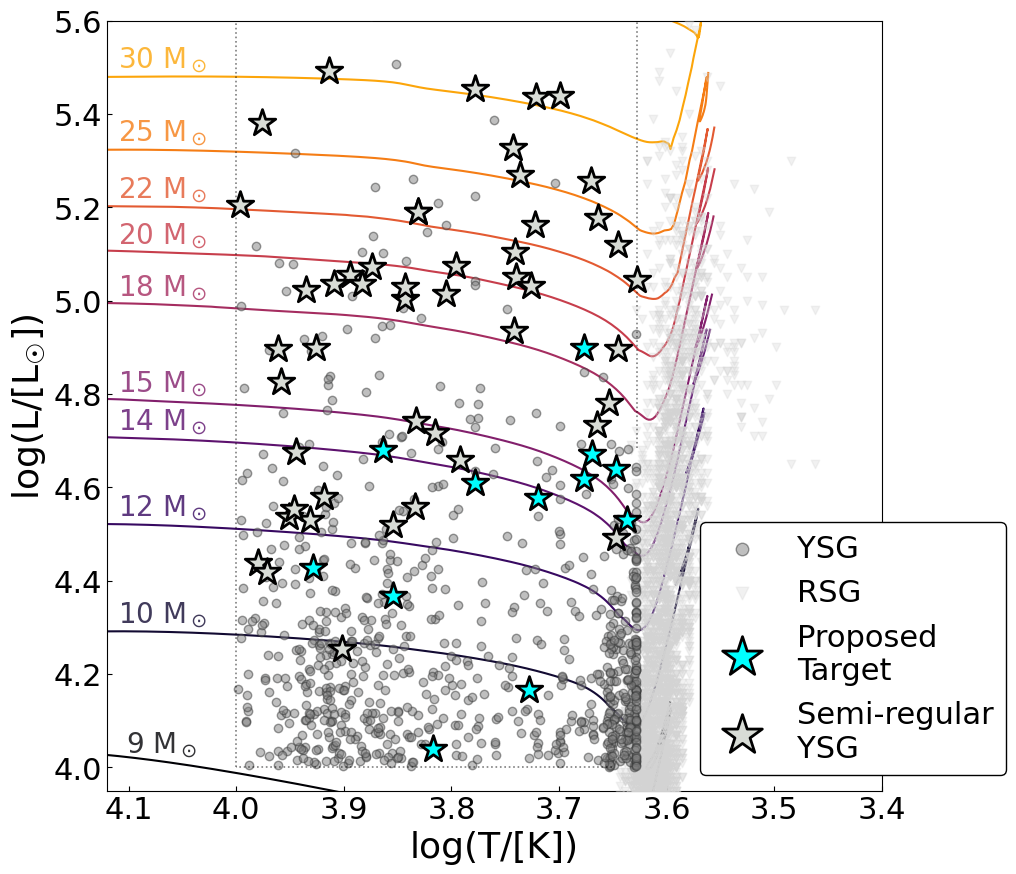

In [37]:
# sample = pd.read_csv(
#     './ysg_candidates_Tcut_nocontaminants_08272026.csv'
# ).set_index('star_idx', drop=False)
# df_smc = stats[stats['RA'] < 40]
# df_lmc = stats[stats['RA'] > 40]


df_smc = sample[sample['RA'] < 40]
df_lmc = sample[sample['RA'] > 40]

def plot_hrd(
    *,
    var_df=None,
    rsg_smc_df=None,
    rsg_lmc_df=None,
    boxes=None,
    box_styles=None,
    proposed_indices=None,
    individual_plotter_func=None,
    figsize=(10, 10),
    width_ratios=(1.15, 1.0),
    hrd_xlim=(4.12, 3.40),
    hrd_ylim=(3.95, 5.6),
    ysg_box=(3.628, 4.00, 4.00, 5.65),
    savepath=None,
    dpi=300,
    report=False,
):
    if var_df is None:
        var_df = sample
    if rsg_smc_df is None:
        rsg_smc_df = rsg_smc
    if rsg_lmc_df is None:
        rsg_lmc_df = rsg_lmc
    if boxes is None:
        boxes = [box3, box1, box2]
    if proposed_indices is None:
        proposed_indices = proposed
    if individual_plotter_func is None:
        individual_plotter_func = individual_plotter

    if box_styles is None:
        box_styles = [
            {"border_color": "xkcd:burnt orange", "bg": "xkcd:light peach", "border_width": 3.0},
            {"border_color": "green", "bg": "xkcd:very light green", "border_width": 3.0},
            {"border_color": "xkcd:violet", "bg": "xkcd:very light purple", "border_width": 3.0},
        ]

    if len(boxes) != 3:
        raise ValueError("Expected exactly 3 boxes (e.g., [box1, box2, box3])")

    fig, ax_hrd = plt.subplots(figsize=figsize)
    gs = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.31)

    # -----------------------------
    # Left panel: HRD
    # -----------------------------
    masses = [9, 10, 12, 14, 15, 18, 20, 22, 25, 30]
    cmap = cm.inferno
    norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)
    cmap = truncate_colormap(cmap, 0.0, 0.8, n=len(masses))

    for i, mass in enumerate(masses):
        postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC_alpha1.5/{mass}M_alpha1.5_wind0.5/LOGS')
        h_postMS = postMSlogdir.history_data

        # only want the parts at log_Teff < 4.25 in the history table
        history_mask = h_postMS.log_Teff < 4.25
        log_Teff = h_postMS.log_Teff[history_mask]
        log_L = h_postMS.log_L[history_mask]
        ax_hrd.plot(log_Teff, log_L, color=cmap(norm(i)), zorder=1)

        x_label = 4.069
        idx_near = (h_postMS.log_Teff - x_label).argmin()
       # instead of nearest-point lookup
        y_label = np.interp(x_label, h_postMS.log_Teff[::-1], h_postMS.log_L[::-1]) 

        # Mass annotation
        ax_hrd.annotate(
            f"{mass}" + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=20,
            color=cmap(norm(i)),
            zorder=20,
            alpha=0.8,
            annotation_clip=False,
        )

    x0, x1, y0, y1 = ysg_box
    mask = var_df[
        (var_df["logT"] > x0)
        & (var_df["logT"] < x1)
        & (var_df["logL"] > y0)
        & (var_df["logL"] < y1)
    ]

    # ax_hrd.add_patch(
    #     Rectangle(
    #         (3.628, 4.0), 0.38, 1.6,
    #         facecolor="none",
    #         edgecolor="black",
    #         alpha=0.5,
    #         zorder=20,
    #         linewidth=1.2,
    #         linestyle="dotted",
    #     )
    # )

    # bottom of box
    bottom_xmin = (4.0 - 116.746)/ -30.885
    right_ymin = -30.885 * np.log10(4250) + 116.746
    ax_hrd.hlines(y=4.0, xmin=bottom_xmin, xmax=4.0, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    #right side of box
    ax_hrd.vlines(x=4.0, ymin=4.0, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    # left side of box
    ax_hrd.vlines(x=3.628, ymin=right_ymin, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")

    # cut_xarray = np.linspace(bottom_xmin, np.log10(4250), mask.shape[0])
    # lmc_fit = -34.596 * cut_xarray + 130.425
    # smc_fit = -30.885 * cut_xarray + 116.746
    # cut_xarray = np.linspace(bottom_xmin, np.log10(4250), mask.shape[0])
    # ax_hrd.plot(cut_xarray, smc_fit, color="black", linestyle="dotted", alpha=0.5, label="SMC Fit", zorder=20)
    # ax_hrd.plot(cut_xarray, lmc_fit, color="black", linestyle="dashed", alpha=0.5, label="LMC Fit", zorder=20)

    ax_hrd.scatter(
        mask["logT"], mask["logL"],
        alpha=0.5,
        color="grey",
        edgecolor="xkcd:dark grey",
        label="YSG",
        zorder=8,
    )

    # RSG comparison samples
    ax_hrd.scatter(
        np.log10(rsg_smc_df["Temp"]), rsg_smc_df["LogLum"],
        alpha=0.3, c="lightgrey", label="RSG", zorder=6, marker="v",
    )
    ax_hrd.scatter(
        np.log10(rsg_lmc_df["Temp"]), rsg_lmc_df["LogLum"],
        alpha=0.3, c="lightgrey", zorder=6, marker="v",
    )

    # Proposed targets
    for star_idx in proposed_indices:
        if star_idx not in var_df.index:
            print(f"Warning: Star index {star_idx} not found in var_df. Skipping.")
            continue
        is_highlighted = star_idx == 307
        ax_hrd.scatter(
            sample.loc[star_idx, "logT"],
            var_df.loc[star_idx, "logL"],
            marker="*",
            s=400,
            c="cyan",
            linewidths=2.0,
            edgecolors="black",
            label="Proposed \nTarget" if is_highlighted else None,
            zorder=100,
        )

    for star in highL_cands:
        if star not in var_df.index:
            continue
        if var_df.loc[star, "logT"] > 4.0:
            print(f"Skipping star {star} for new_highL_cands because logT > 4.0")
            continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
            label = 'Semi-regular\nYSG'
        )
    for star in new_highL_cands:
        if star not in var_df.index:
            continue
        if var_df.loc[star, "logT"] > 4.0:
            print(f"Skipping star {star} for new_highL_cands because logT > 4.0")
            continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
        )

    box_star_indices = [307, 780, 716]
    box_star_colours = ["xkcd:very light green", "xkcd:very light purple", "xkcd:light peach"]
    box_star_ecolors = ["green", "xkcd:violet", "xkcd:burnt orange"]
    box_dx, box_dy = 0.07, 0.15

    # for box_idx, facecol, ecol in zip(box_star_indices, box_star_colours, box_star_ecolors):
    #     if box_idx not in var_df.index:
    #         continue
    #     x0b = var_df.loc[box_idx, "logT"]
    #     y0b = var_df.loc[box_idx, "logL"]
    #     if pd.isna(x0b) or pd.isna(y0b):
    #         continue
    #     ax_hrd.add_patch(
    #         Rectangle(
    #             (x0b - box_dx / 2, y0b - box_dy / 2),
    #             box_dx, box_dy,
    #             facecolor=facecol,
    #             edgecolor=ecol,
    #             alpha=0.9,
    #             zorder=2,
    #             linewidth=1.5,
    #         )
    #     )

    ax_hrd.invert_xaxis()
    ax_hrd.set_xlim(*hrd_xlim)
    ax_hrd.set_ylim(*hrd_ylim)
    ax_hrd.tick_params(axis="both", direction="in", labelsize=22)
    ax_hrd.set_xlabel("log(T/[K])", fontsize=26)
    ax_hrd.set_ylabel("log(L/[L$_☉$])", fontsize=26)

    # Fixed-order legend
    handles, labels = ax_hrd.get_legend_handles_labels()
    label_to_handle = {}
    for h, lab in zip(handles, labels):
        if lab and (lab not in label_to_handle):
            label_to_handle[lab] = h

    wanted = ["YSG", "RSG", "Proposed \nTarget", "Semi-regular\nYSG"] #"Known SN \nProgenitor",
    ordered_handles = [label_to_handle[l] for l in wanted if l in label_to_handle]
    ordered_labels = [l for l in wanted if l in label_to_handle]

    leg = ax_hrd.legend(
        ordered_handles, ordered_labels,
        bbox_to_anchor=(1.18, 0.0),
        loc="lower right",
        title_fontsize=16,
        fontsize=22,
        markerscale=1.5,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="black",
    )
    leg.set_zorder(200)

    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")



plot_hrd(var_df = sample, report=False, savepath="./jared_meeting/HRD_gemini.png", dpi=600)

# all YSGs, including those that will be cut:

BadPathError: (BadPathError(...), '../../ysg_mesa_LMC/9M_alpha2.1_wind0.5/LOGS is not a valid directory.')

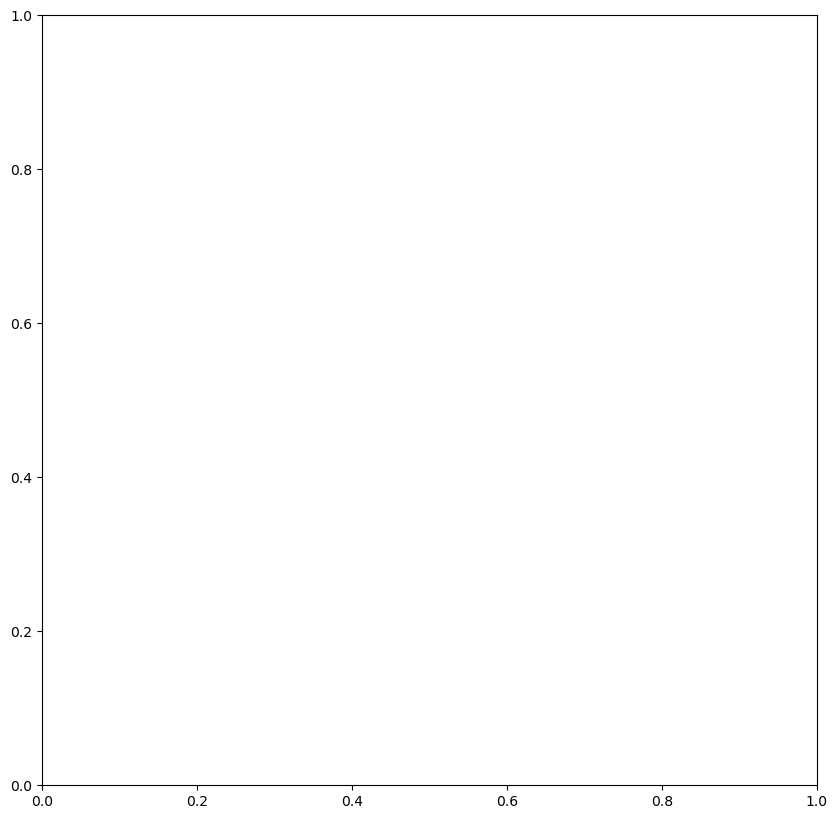

In [38]:
sample = pd.read_csv(
    './summary_results08182026.csv'
).set_index('star_idx', drop=False)
# df_smc = stats[stats['RA'] < 40]
# df_lmc = stats[stats['RA'] > 40]
df_lmc = sample[sample['RA'] > 40]

def plot_hrd_lmc(
    *,
    var_df=None,
    rsg_lmc_df=None,
    boxes=None,
    box_styles=None,
    proposed_indices=None,
    individual_plotter_func=None,
    figsize=(10, 10),
    width_ratios=(1.15, 1.0),
    hrd_xlim=(4.12, 3.40),
    hrd_ylim=(3.95, 5.6),
    ysg_box=(3.628, 4.00, 4.00, 5.65),
    savepath=None,
    dpi=300,
    report=False,
):
    if var_df is None:
        var_df = df_lmc
    if rsg_lmc_df is None:
        rsg_lmc_df = rsg_lmc
    if boxes is None:
        boxes = [box3, box1, box2]
    if proposed_indices is None:
        proposed_indices = proposed
    if individual_plotter_func is None:
        individual_plotter_func = individual_plotter

    if box_styles is None:
        box_styles = [
            {"border_color": "xkcd:burnt orange", "bg": "xkcd:light peach", "border_width": 3.0},
            {"border_color": "green", "bg": "xkcd:very light green", "border_width": 3.0},
            {"border_color": "xkcd:violet", "bg": "xkcd:very light purple", "border_width": 3.0},
        ]

    if len(boxes) != 3:
        raise ValueError("Expected exactly 3 boxes (e.g., [box1, box2, box3])")

    fig, ax_hrd = plt.subplots(figsize=figsize)
    gs = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.31)

    # -----------------------------
    # Left panel: HRD
    # -----------------------------
    masses = [9, 10, 12, 14, 15, 18, 20, 22, 25, 30]
    cmap = cm.inferno
    norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)
    cmap = truncate_colormap(cmap, 0.0, 0.8, n=len(masses))

    for i, mass in enumerate(masses):
        postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_LMC/{mass}M_alpha2.1_wind0.5/LOGS')
        h_postMS = postMSlogdir.history_data

        # only want the parts at log_Teff < 4.25 in the history table
        history_mask = h_postMS.log_Teff < 4.25
        log_Teff = h_postMS.log_Teff[history_mask]
        log_L = h_postMS.log_L[history_mask]
        ax_hrd.plot(log_Teff, log_L, color=cmap(norm(i)), zorder=1)

        x_label = 4.069
        idx_near = (h_postMS.log_Teff - x_label).argmin()
       # instead of nearest-point lookup
        y_label = np.interp(x_label, h_postMS.log_Teff[::-1], h_postMS.log_L[::-1]) 

        # Mass annotation
        ax_hrd.annotate(
            f"{mass}" + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=20,
            color=cmap(norm(i)),
            zorder=20,
            alpha=0.8,
            annotation_clip=False,
        )

    x0, x1, y0, y1 = ysg_box
    mask = var_df[
        (var_df["logT"] > x0)
        & (var_df["logT"] < x1)
        & (var_df["logL"] > y0)
        & (var_df["logL"] < y1)
    ]

    # ax_hrd.add_patch(
    #     Rectangle(
    #         (3.628, 4.0), 0.38, 1.6,
    #         facecolor="none",
    #         edgecolor="black",
    #         alpha=0.5,
    #         zorder=20,
    #         linewidth=1.2,
    #         linestyle="dotted",
    #     )
    # )

    # bottom of box
    bottom_xmin = (4.0 - 116.746)/ -30.885
    bottom_xmin_lmc = (4.0 - 130.425)/ -34.596
    right_ymin = -30.885 * np.log10(4250) + 116.746
    ax_hrd.hlines(y=4.0, xmin=bottom_xmin, xmax=4.0, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    #right side of box
    ax_hrd.vlines(x=4.0, ymin=4.0, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    # left side of box
    ax_hrd.vlines(x=3.628, ymin=right_ymin, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")

    cut_xarray = np.linspace(bottom_xmin_lmc, np.log10(4250), mask.shape[0])
    # LMC: log_L = -34.596 * log_Teff + 130.425  (n=11)
    # SMC: log_L = -30.885 * log_Teff + 116.746   
    lmc_fit = -34.596 * cut_xarray + 130.425
    # ax_hrd.plot(mask["logT"], lmc_fit, color="black", linestyle="--", alpha=0.8, label="LMC Fit", zorder=15)
    # ax_hrd.plot(mask["logT"], smc_fit, color="black", linestyle="--", alpha=0.8, label="SMC Fit", zorder=15)
    cut_xarray = np.linspace(bottom_xmin_lmc, np.log10(4250), mask.shape[0])
    ax_hrd.plot(cut_xarray, lmc_fit, color="red", linestyle="dashed", alpha=0.9, linewidth=2.0, label="LMC Fit", zorder=20)

    # ax_hrd.scatter(
    #     mask["logT"], mask["logL"],
    #     alpha=0.5,
    #     color="grey",
    #     edgecolor="xkcd:dark grey",
    #     label="YSG",
    #     zorder=8,
    # )

    ax_hrd.scatter(df_lmc["logT"], df_lmc["logL"], alpha=0.5, color="grey", edgecolor="xkcd:dark grey", label="YSG", zorder=8)


    ax_hrd.scatter(
        np.log10(rsg_lmc_df["Temp"]), rsg_lmc_df["LogLum"],
        alpha=0.3, c="lightgrey", zorder=6, marker="v",
    )

    # Proposed targets
    for star_idx in proposed_indices:
        if star_idx not in var_df.index:
            print(f"Warning: Star index {star_idx} not found in var_df. Skipping.")
            continue
        # if var_df.loc[star, "RA"] < 40:
        #     continue
        is_highlighted = star_idx ==1130
        ax_hrd.scatter(
            sample.loc[star_idx, "logT"],
            var_df.loc[star_idx, "logL"],
            marker="*",
            s=400,
            c="cyan",
            linewidths=2.0,
            edgecolors="black",
            label="Proposed \nTarget" if is_highlighted else None,
            zorder=100,
        )

    for star in highL_cands:
        if star not in var_df.index:
            continue
        # check if in lmc
        # if var_df.loc[star_idx, "RA"] < 40:
        #     continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
            label = 'Semi-regular\nYSG'
        )

    box_star_indices = [307, 780, 716]
    box_star_colours = ["xkcd:very light green", "xkcd:very light purple", "xkcd:light peach"]
    box_star_ecolors = ["green", "xkcd:violet", "xkcd:burnt orange"]
    box_dx, box_dy = 0.07, 0.15

    # for box_idx, facecol, ecol in zip(box_star_indices, box_star_colours, box_star_ecolors):
    #     if box_idx not in var_df.index:
    #         continue
    #     x0b = var_df.loc[box_idx, "logT"]
    #     y0b = var_df.loc[box_idx, "logL"]
    #     if pd.isna(x0b) or pd.isna(y0b):
    #         continue
    #     ax_hrd.add_patch(
    #         Rectangle(
    #             (x0b - box_dx / 2, y0b - box_dy / 2),
    #             box_dx, box_dy,
    #             facecolor=facecol,
    #             edgecolor=ecol,
    #             alpha=0.9,
    #             zorder=2,
    #             linewidth=1.5,
    #         )
    #     )
    ax_hrd.text(3.55, 5.4, "LMC", fontsize=35, fontweight="bold", color="black", zorder=200)
    ax_hrd.invert_xaxis()
    ax_hrd.set_xlim(*hrd_xlim)
    ax_hrd.set_ylim(*hrd_ylim)
    ax_hrd.tick_params(axis="both", direction="in", labelsize=22)
    ax_hrd.set_xlabel("log(T/[K])", fontsize=26)
    ax_hrd.set_ylabel("log(L/[L$_☉$])", fontsize=26)

    # Fixed-order legend
    handles, labels = ax_hrd.get_legend_handles_labels()
    label_to_handle = {}
    for h, lab in zip(handles, labels):
        if lab and (lab not in label_to_handle):
            label_to_handle[lab] = h

    wanted = ["YSG", "RSG", "Proposed \nTarget", "Semi-regular\nYSG"] #"Known SN \nProgenitor",
    ordered_handles = [label_to_handle[l] for l in wanted if l in label_to_handle]
    ordered_labels = [l for l in wanted if l in label_to_handle]

    leg = ax_hrd.legend(
        ordered_handles, ordered_labels,
        bbox_to_anchor=(1.18, 0.0),
        loc="lower right",
        title_fontsize=16,
        fontsize=22,
        markerscale=1.5,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="black",
    )
    leg.set_zorder(200)

    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    plt.show()



sample_lmc = sample.loc[sample["RA"] > 40].copy()
plot_hrd_lmc(var_df = sample_lmc, report=False, savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_LMC.png", dpi=600)

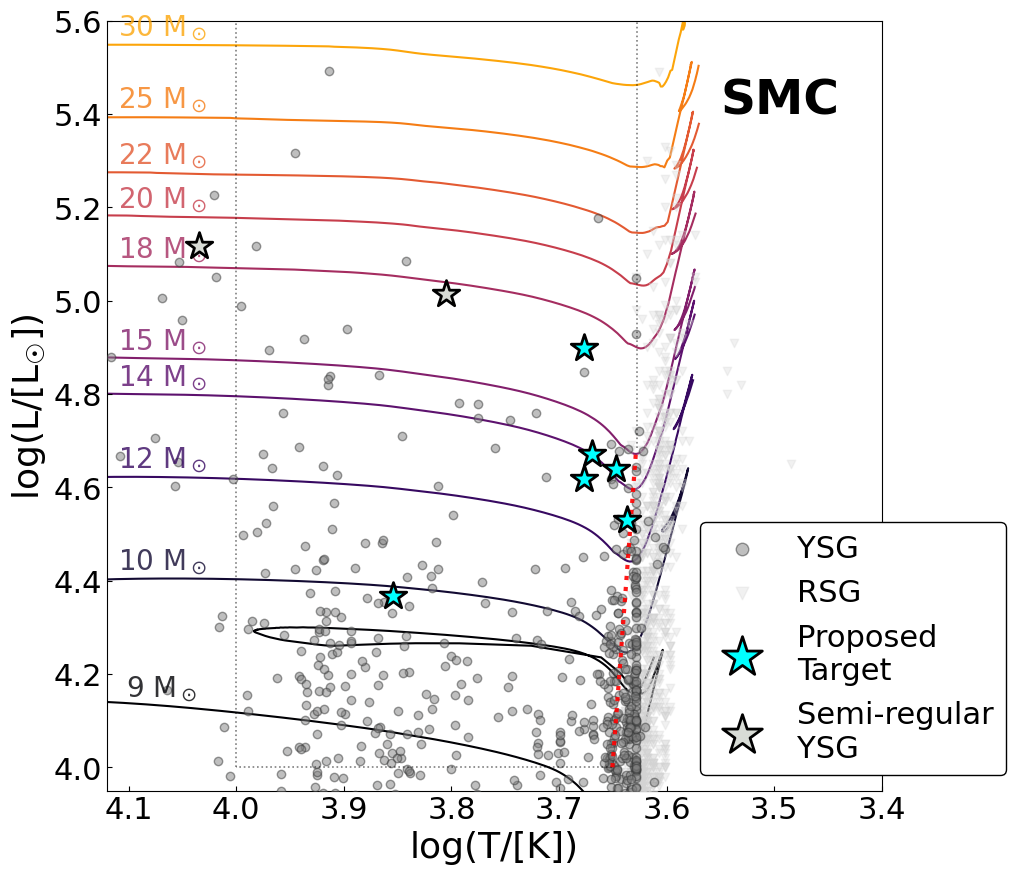

In [ ]:
sample = pd.read_csv(
    './summary_results08182026.csv'
).set_index('star_idx', drop=False)
# df_smc = stats[stats['RA'] < 40]
# df_lmc = stats[stats['RA'] > 40]


df_smc = sample[sample['RA'] < 40]


def plot_hrd_smc(
    *,
    var_df=None,
    rsg_smc_df=None,
    rsg_lmc_df=None,
    boxes=None,
    box_styles=None,
    proposed_indices=None,
    individual_plotter_func=None,
    figsize=(10, 10),
    width_ratios=(1.15, 1.0),
    hrd_xlim=(4.12, 3.40),
    hrd_ylim=(3.95, 5.6),
    ysg_box=(3.628, 4.00, 4.00, 5.65),
    savepath=None,
    dpi=300,
    report=False,
):
    if var_df is None:
        var_df = df_smc
    if rsg_smc_df is None:
        rsg_smc_df = rsg_smc

    if boxes is None:
        boxes = [box3, box1, box2]
    if proposed_indices is None:
        proposed_indices = proposed
    if individual_plotter_func is None:
        individual_plotter_func = individual_plotter

    if box_styles is None:
        box_styles = [
            {"border_color": "xkcd:burnt orange", "bg": "xkcd:light peach", "border_width": 3.0},
            {"border_color": "green", "bg": "xkcd:very light green", "border_width": 3.0},
            {"border_color": "xkcd:violet", "bg": "xkcd:very light purple", "border_width": 3.0},
        ]

    if len(boxes) != 3:
        raise ValueError("Expected exactly 3 boxes (e.g., [box1, box2, box3])")

    fig, ax_hrd = plt.subplots(figsize=figsize)
    gs = GridSpec(1, 2, figure=fig, width_ratios=width_ratios, wspace=0.31)

    # -----------------------------
    # Left panel: HRD
    # -----------------------------
    masses = [9, 10, 12, 14, 15, 18, 20, 22, 25, 30]
    cmap = cm.inferno
    norm = mcolors.Normalize(vmin=0, vmax=len(masses) - 1)
    cmap = truncate_colormap(cmap, 0.0, 0.8, n=len(masses))

    for i, mass in enumerate(masses):
        postMSlogdir = mr.MesaLogDir(f'../../ysg_mesa_SMC/{mass}M_alpha2.1_wind0.5/LOGS')
        h_postMS = postMSlogdir.history_data

        # only want the parts at log_Teff < 4.25 in the history table
        history_mask = h_postMS.log_Teff < 4.25
        log_Teff = h_postMS.log_Teff[history_mask]
        log_L = h_postMS.log_L[history_mask]
        ax_hrd.plot(log_Teff, log_L, color=cmap(norm(i)), zorder=1)

        x_label = 4.069
        idx_near = (h_postMS.log_Teff - x_label).argmin()
       # instead of nearest-point lookup
        y_label = np.interp(x_label, h_postMS.log_Teff[::-1], h_postMS.log_L[::-1]) 

        # Mass annotation
        ax_hrd.annotate(
            f"{mass}" + r" M$_\odot$",
            xy=(x_label, y_label),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=20,
            color=cmap(norm(i)),
            zorder=20,
            alpha=0.8,
            annotation_clip=False,
        )

    x0, x1, y0, y1 = ysg_box
    mask = var_df[
        (var_df["logT"] > x0)
        & (var_df["logT"] < x1)
        & (var_df["logL"] > y0)
        & (var_df["logL"] < y1)
    ]

    # ax_hrd.add_patch(
    #     Rectangle(
    #         (3.628, 4.0), 0.38, 1.6,
    #         facecolor="none",
    #         edgecolor="black",
    #         alpha=0.5,
    #         zorder=20,
    #         linewidth=1.2,
    #         linestyle="dotted",
    #     )
    # )

    # bottom of box
    bottom_xmin = (4.0 - 116.746)/ -30.885
    right_ymin = -30.885 * np.log10(4250) + 116.746
    ax_hrd.hlines(y=4.0, xmin=bottom_xmin, xmax=4.0, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    #right side of box
    ax_hrd.vlines(x=4.0, ymin=4.0, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")
    # left side of box
    ax_hrd.vlines(x=3.628, ymin=right_ymin, ymax=5.65, color="black", alpha=0.5, zorder=20, linewidth=1.2, linestyle="dotted")

    cut_xarray = np.linspace(bottom_xmin, np.log10(4250), mask.shape[0])
    # LMC: log_L = -34.596 * log_Teff + 130.425  (n=11)
    # SMC: log_L = -30.885 * log_Teff + 116.746   
    smc_fit = -30.885 * cut_xarray + 116.746
    # ax_hrd.plot(mask["logT"], lmc_fit, color="black", linestyle="--", alpha=0.8, label="LMC Fit", zorder=15)
    # ax_hrd.plot(mask["logT"], smc_fit, color="black", linestyle="--", alpha=0.8, label="SMC Fit", zorder=15)
    cut_xarray = np.linspace(bottom_xmin, np.log10(4250), mask.shape[0])
    ax_hrd.plot(cut_xarray, smc_fit, color="red", linestyle="dotted", alpha=0.9, linewidth=3.0, label="SMC Fit", zorder=20)

    ax_hrd.scatter(
        var_df["logT"], var_df["logL"],
        alpha=0.5,
        color="grey",
        edgecolor="xkcd:dark grey",
        label="YSG",
        zorder=8,
    )

    # RSG comparison samples
    ax_hrd.scatter(
        np.log10(rsg_smc_df["Temp"]), rsg_smc_df["LogLum"],
        alpha=0.3, c="lightgrey", label="RSG", zorder=6, marker="v",
    )
    # ax_hrd.scatter(
    #     np.log10(rsg_lmc_df["Temp"]), rsg_lmc_df["LogLum"],
    #     alpha=0.3, c="lightgrey", zorder=6, marker="v",
    # )

    # Proposed targets
    for star_idx in proposed_indices:
        if star_idx not in var_df.index:
            print(f"Warning: Star index {star_idx} not found in var_df. Skipping.")
            continue
        is_highlighted = star_idx == 307 or star_idx == 716 or star_idx == 1130
        ax_hrd.scatter(
            var_df.loc[star_idx, "logT"],
            var_df.loc[star_idx, "logL"],
            marker="*",
            s=400,
            c="cyan",
            linewidths=2.0,
            edgecolors="black",
            label="Proposed \nTarget" if is_highlighted else None,
            zorder=100,
        )

    for star in highL_cands:
        if star not in var_df.index:
            
            continue
        ax_hrd.scatter(
            var_df.loc[star, "logT"],
            var_df.loc[star, "logL"],
            marker="*",
            s=400,
            c="xkcd:light grey",
            linewidths=2.0,
            edgecolors="black",
            zorder=100,
            label = 'Semi-regular\nYSG'
        )

    box_star_indices = [307, 780, 716]
    box_star_colours = ["xkcd:very light green", "xkcd:very light purple", "xkcd:light peach"]
    box_star_ecolors = ["green", "xkcd:violet", "xkcd:burnt orange"]
    box_dx, box_dy = 0.07, 0.15

    # for box_idx, facecol, ecol in zip(box_star_indices, box_star_colours, box_star_ecolors):
    #     if box_idx not in var_df.index:
    #         continue
    #     x0b = var_df.loc[box_idx, "logT"]
    #     y0b = var_df.loc[box_idx, "logL"]
    #     if pd.isna(x0b) or pd.isna(y0b):
    #         continue
    #     ax_hrd.add_patch(
    #         Rectangle(
    #             (x0b - box_dx / 2, y0b - box_dy / 2),
    #             box_dx, box_dy,
    #             facecolor=facecol,
    #             edgecolor=ecol,
    #             alpha=0.9,
    #             zorder=2,
    #             linewidth=1.5,
    #         )
    #     )
    ax_hrd.text(3.55, 5.4, "SMC", fontsize=35, fontweight="bold", color="black", zorder=200)
    ax_hrd.invert_xaxis()
    ax_hrd.set_xlim(*hrd_xlim)
    ax_hrd.set_ylim(*hrd_ylim)
    ax_hrd.tick_params(axis="both", direction="in", labelsize=22)
    ax_hrd.set_xlabel("log(T/[K])", fontsize=26)
    ax_hrd.set_ylabel("log(L/[L$_☉$])", fontsize=26)

    # Fixed-order legend
    handles, labels = ax_hrd.get_legend_handles_labels()
    label_to_handle = {}
    for h, lab in zip(handles, labels):
        if lab and (lab not in label_to_handle):
            label_to_handle[lab] = h

    wanted = ["YSG", "RSG", "Proposed \nTarget", "Semi-regular\nYSG"] #"Known SN \nProgenitor",
    ordered_handles = [label_to_handle[l] for l in wanted if l in label_to_handle]
    ordered_labels = [l for l in wanted if l in label_to_handle]

    leg = ax_hrd.legend(
        ordered_handles, ordered_labels,
        bbox_to_anchor=(1.18, 0.0),
        loc="lower right",
        title_fontsize=16,
        fontsize=22,
        markerscale=1.5,
        frameon=True,
        framealpha=1.0,
        facecolor="white",
        edgecolor="black",
    )
    leg.set_zorder(200)

    fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    plt.show()


sample_smc = sample.loc[sample["RA"] < 40].copy()
plot_hrd_smc(var_df = sample_smc, report=False, savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_SMC.png", dpi=600)

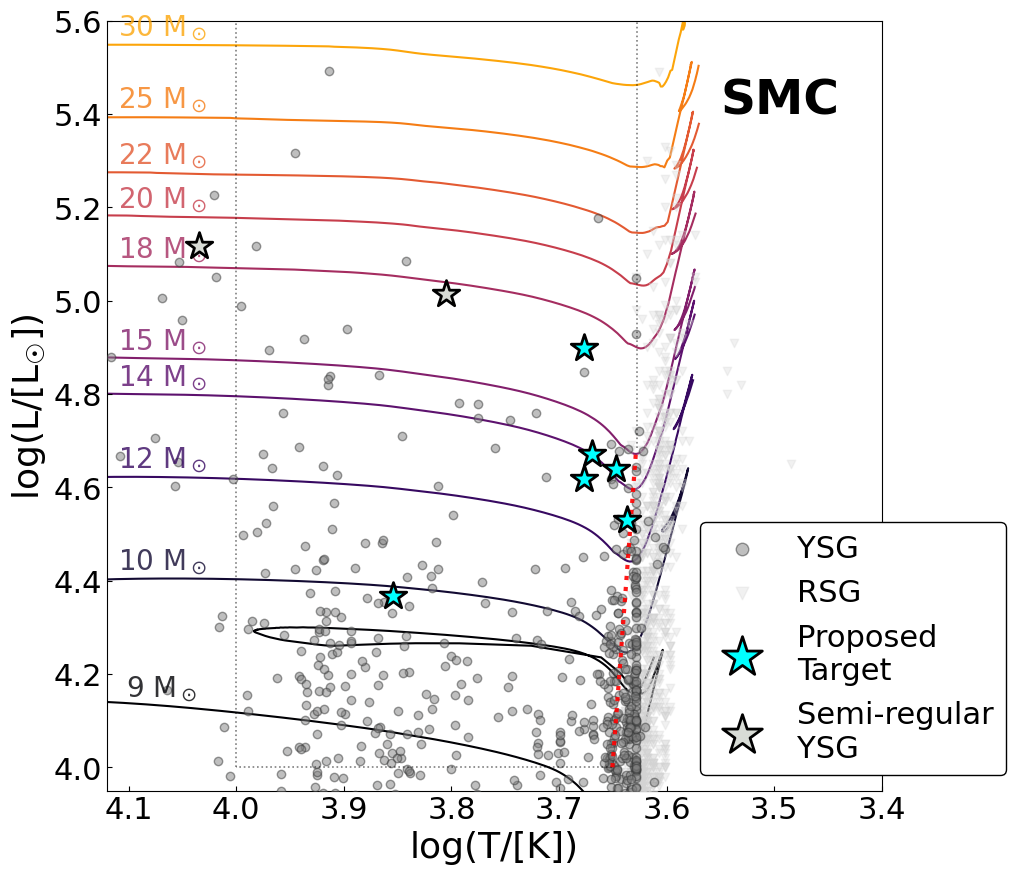

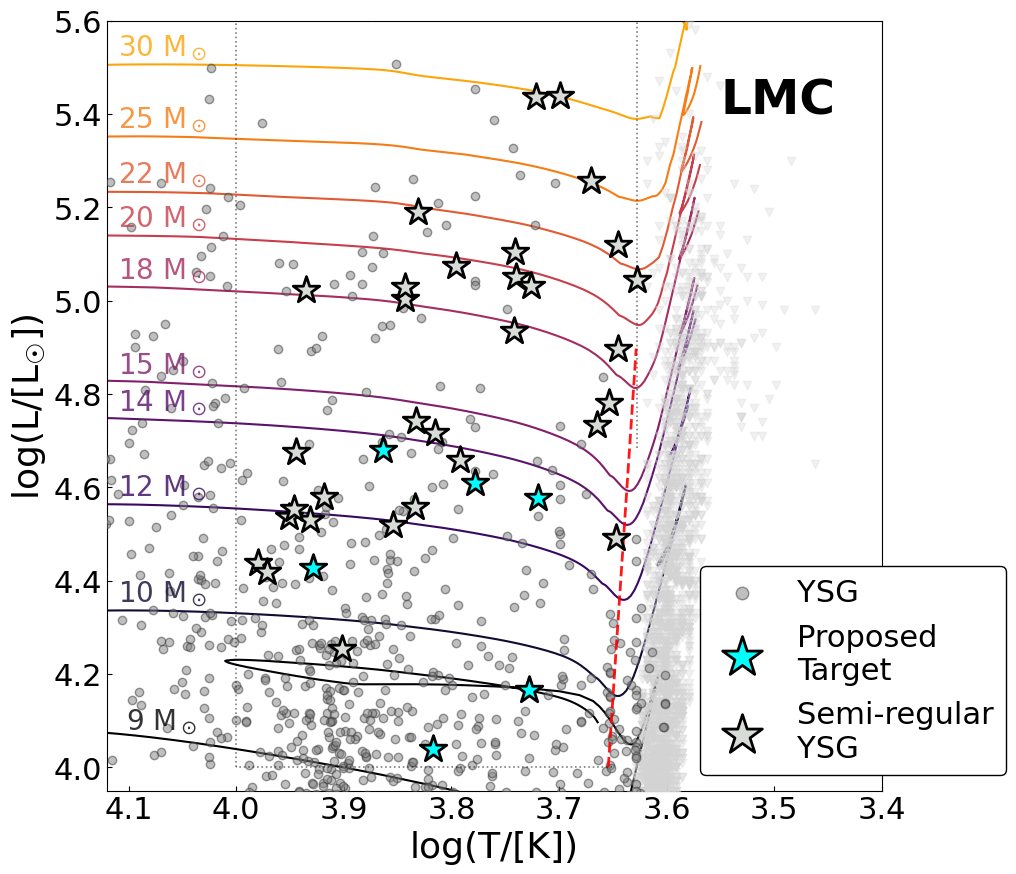

In [ ]:
# Restrict the plotted YSG sample to the SMC before calling the plotting function.
sample_smc = sample.loc[sample["RA"] < 40].copy()

plot_hrd_smc(
    var_df=sample_smc,
    report=False,
    savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_SMC.png",
    dpi=600,
 )

sample_lmc = sample.loc[sample["RA"] > 40].copy()
plot_hrd_lmc(
    var_df=sample_lmc,
    report=False,
    savepath="./figs/hr_diagrams/plot_HRD_cropped_allYSGs_LMC.png",
    dpi=600,
)

# TZO-like plot

In [ ]:
mesa_dir = "Users/shannonbowes/Research/ysg/ysg_mesa_SMC"


# "boat" plot

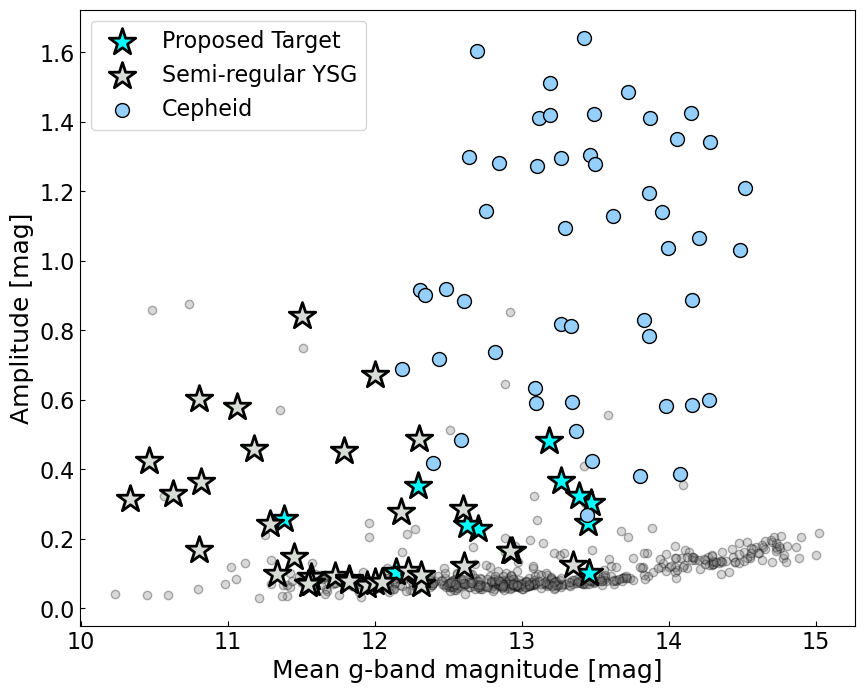

In [39]:
sample = pd.read_csv(
    './ysg_candidates_Tcut_nocontaminants_08272026.csv'
).set_index('star_idx', drop=False)

sample = sample[~pd.isna(sample['logT'])]


# mag vs amplitude plot
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(sample['overall_mean_mag'], sample['mag_amplitude_1'], alpha=0.3, color='grey', edgecolor='black')

proposed_stars = [s for s in proposed if s in sample.index and not pd.isna(sample.loc[s, "logT"])]

# is_highlighted = star_idx == 307 or star_idx == 716 or star_idx == 1130
ax.scatter(
    sample.loc[proposed_stars, "overall_mean_mag"],
    sample.loc[proposed_stars, "mag_amplitude_1"],
    marker="*",
    s=400,
    c="cyan",
    linewidths=2.0,
    edgecolors="black",
    label="Proposed Target",
    zorder=100,
)

stars = [s for s in highL_cands if s in sample.index and not pd.isna(sample.loc[s, "logT"])]
ax.scatter(
    sample.loc[stars, "overall_mean_mag"],
    sample.loc[stars, "mag_amplitude_1"],
    marker="*",
    s=400,
    c="xkcd:light grey",
    linewidths=2.0,
    edgecolors="black",
    zorder=100,
    label = 'Semi-regular YSG'
)

cepheids = sample["SIMBAD_maintype"] == "ClassicalCep"
ax.scatter(
    sample.loc[cepheids, "overall_mean_mag"],
    sample.loc[cepheids, "mag_amplitude_1"],
    marker="o",
    s=100,
    c="xkcd:light blue",
    linewidths=1.0,
    edgecolors="black",
    zorder=100,
    label = 'Cepheid'
)

ax.legend(loc = 'upper left', fontsize=16)
ax.set_xlabel("Mean g-band magnitude [mag]", fontsize=18)
ax.set_ylabel("Amplitude [mag]", fontsize=18)
ax.tick_params(axis="both", direction="in", labelsize=16)
plt.savefig("./jared_meeting/mag_vs_amplitude.png", dpi=300, bbox_inches="tight")

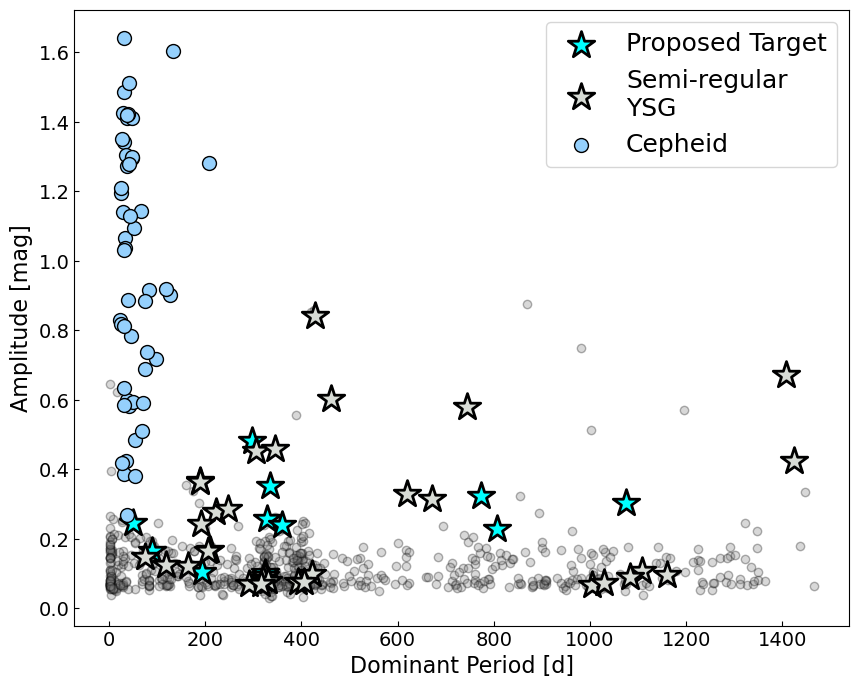

In [41]:
# period vs amplitude

sample = pd.read_csv(
    './summary_results08182026.csv'
).set_index('star_idx', drop=False)


# mag vs amplitude plot
fig, ax = plt.subplots(figsize=(10, 8))
# mask out nan temperature
sample = sample[~pd.isna(sample['logT'])]
sample = sample[sample['logT']>np.log10(4250)]
sample = sample[sample['logT']<4.0]
sample = sample[sample['logL']>4.0]
ax.scatter(sample['best_period'], sample['mag_amplitude_1'], alpha=0.3, color='grey', edgecolor='black')

proposed_stars = [s for s in proposed if s in sample.index and not pd.isna(sample.loc[s, "logT"])]
ax.scatter(
    sample.loc[proposed_stars, "best_period"],
    sample.loc[proposed_stars, "mag_amplitude_1"],
    marker="*",
    s=400,
    c="cyan",
    linewidths=2.0,
    edgecolors="black",
    label="Proposed Target", 
    zorder=100,
)

stars = [s for s in highL_cands if s in sample.index and not pd.isna(sample.loc[s, "logT"])]

ax.scatter(
    sample.loc[stars, "best_period"],
    sample.loc[stars, "mag_amplitude_1"],
    marker="*",
    s=400,
    c="xkcd:light grey",
    linewidths=2.0,
    edgecolors="black",
    zorder=100,
    label='Semi-regular\nYSG',
)

cepheids = sample["SIMBAD_maintype"] == "ClassicalCep"
ax.scatter(
    sample.loc[cepheids, "best_period"],
    sample.loc[cepheids, "mag_amplitude_1"],
    marker="o",
    s=100,
    c="xkcd:light blue",
    linewidths=1.0,
    edgecolors="black",
    zorder=100,
    label = 'Cepheid'
)

ax.legend(fontsize=18)
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Amplitude [mag]", fontsize=16)
ax.tick_params(axis="both", direction="in", labelsize=14)
plt.savefig("./jared_meeting/mag_vs_amplitude.png", dpi=300, bbox_inches="tight")

Number of stars in first bin (0-10 days): 22


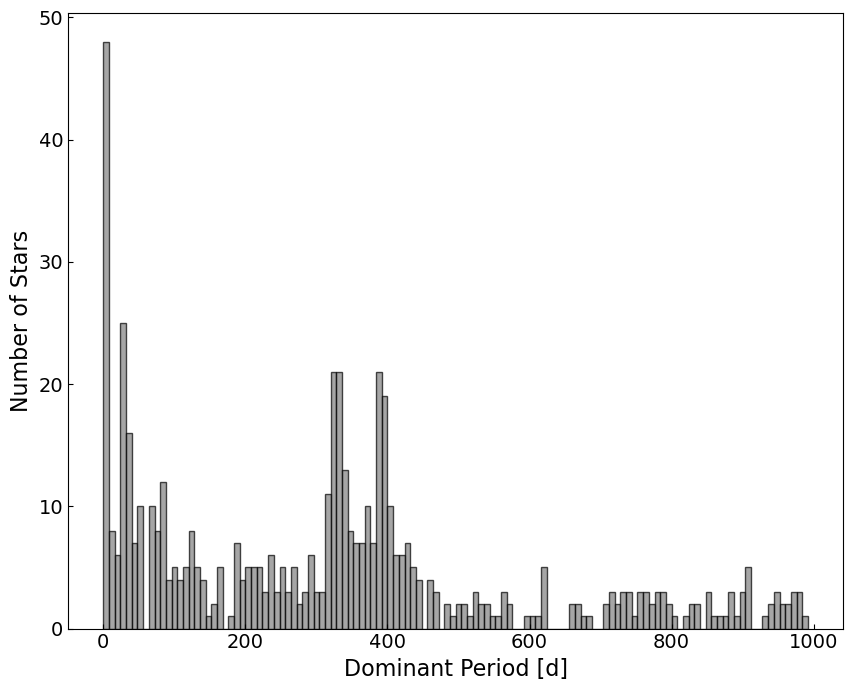

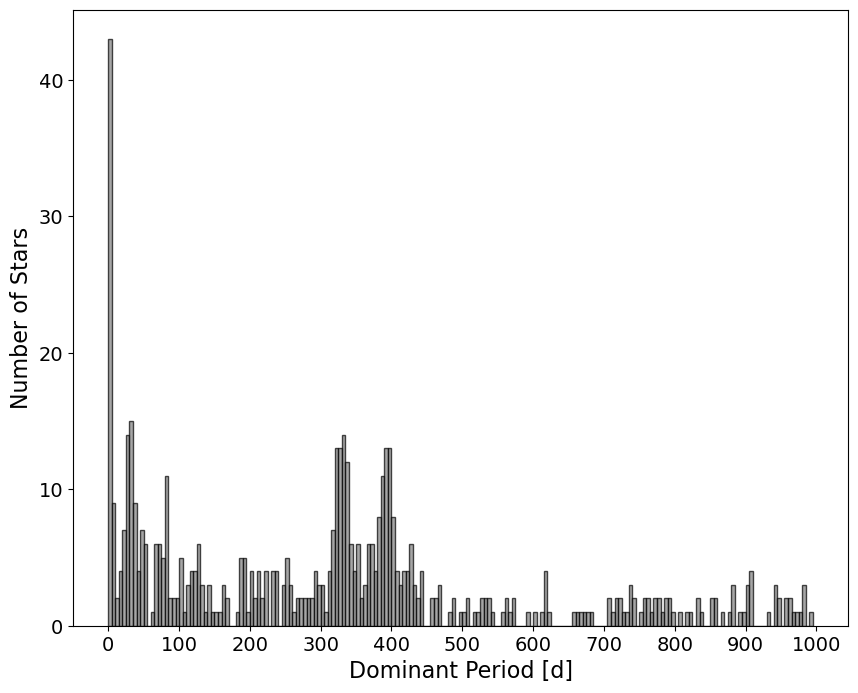

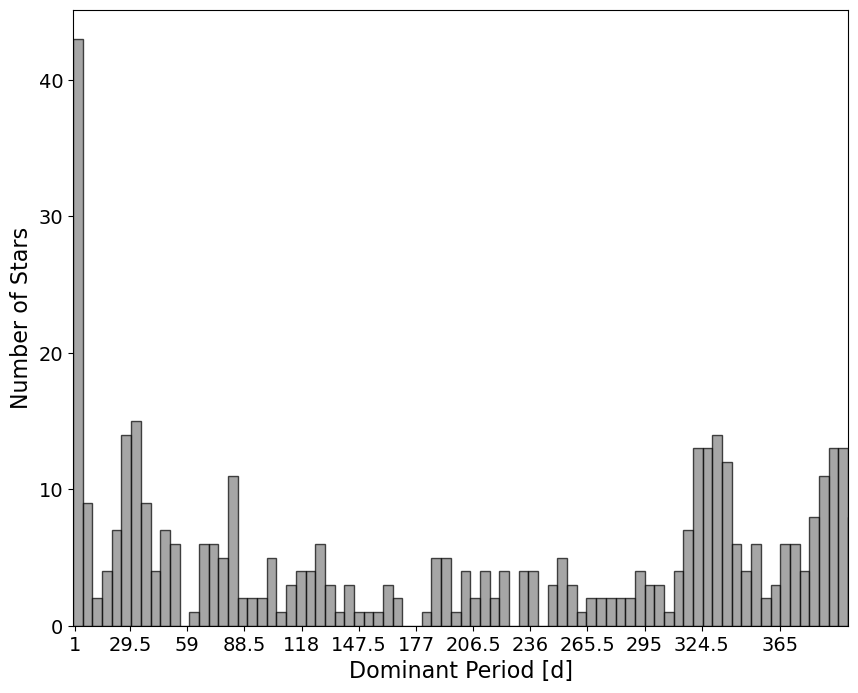

In [104]:
# histogram of periods

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 8), alpha=0.7, color='grey', edgecolor='black')
# print the number ni the first bin
print(f"Number of stars in first bin (0-10 days): {np.sum((sample['best_period'] >= 0) & (sample['best_period'] < 2))}")
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="in", labelsize=14)
plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
# ax.set_xlim(0,400)
# diy markers on the x axis
# xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
# ax.set_xticks(xticks)
# ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
ax.set_xticks(np.arange(0, 1001, 100))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
ax.hist(sample['best_period'], bins=np.arange(0, 1000, 5), alpha=0.7, color='grey', edgecolor='black')
ax.set_xlabel("Dominant Period [d]", fontsize=16)
ax.set_ylabel("Number of Stars", fontsize=16)
ax.tick_params(axis="both", direction="out", labelsize=14)
ax.set_xlim(0,400)
# diy markers on the x axis
xticks = [1.0, 29.5, 29.5*2, 29.5*3, 29.5*4, 29.5*5, 29.5*6, 29.5*7, 29.5*8, 29.5*9, 29.5*10, 29.5*11, 365]
ax.set_xticks(xticks)
ax.set_xticklabels(['1', '29.5', '59', '88.5', '118', '147.5', '177', '206.5', '236', '265.5', '295', '324.5', '365'])
# ax.set_xticks(np.arange(0, 401, 50))
# plt.savefig("./figs/period_histogram.png", dpi=300, bbox_inches="tight")
plt.show()